# Problemas de Busca

Este notebook reúne os algoritmos de busca clássicos e quânticos discutidos no capítulo 3. Os componentes quânticos são simulados com PennyLane. As comparações de custo usam o modelo de consultas ou o tempo hamiltoniano do modelo teórico correspondente. O tempo de simulação clássica é medido e apresentado separadamente.

## Sumário

0. [Configuração e convenções](#sec-0)
1. [Busca não estruturada: exaustiva, aleatorizada e Grover](#sec-1)
2. [Busca de mínimos por Dürr e Høyer](#sec-2)
3. [Busca estruturada em espaços implícitos: BFS, DFS, A* e passeio aleatório](#sec-3)
4. [Passeio clássico e caminhada quântica discreta na reta](#sec-4)
5. [Caminhada quântica discreta no hipercubo e no reticulado toroidal](#sec-5)
6. [Busca adversarial, árvores AND-OR e fórmulas NAND](#sec-6)
7. [Caminhada quântica em tempo contínuo na reta e no reticulado](#sec-7)
8. [Avaliação de árvores NAND por espalhamento](#sec-8)
9. [Verificações, ambiente e tempo de execução](#sec-9)
10. [Referências](#sec-10)

## Configuração e convenções

### Unidades de custo


| Grandeza | Significado | Onde aparece |
| --- | --- | --- |
| Consulta ao oráculo | Uma avaliação do predicado $f$ ou uma aplicação do operador de fase $O_f$ | Seções 1 e 2 |
| Expansão de estado | Retirada de um estado da fronteira seguida da geração de seus sucessores | Seção 3 |
| Chamada à função de sucessores | Uma invocação de `sucessores(v)` | Seção 3 |
| Passo de caminhada | Uma aplicação do operador de evolução discreta $U = S\,C$ ou um passo do passeio clássico | Seções 3, 4 e 5 |
| Tempo hamiltoniano | Parâmetro $t$ de $e^{-iHt}$, adimensional, com $\hbar = 1$ e $\gamma = 1$ salvo indicação | Seções 7 e 8 |
| Execução de circuito | Uma chamada a um QNode | Todas as seções quânticas |
| Shot | Uma amostra de medição obtida em uma execução | Seções 1 e 2 |
| Tempo de simulação | Tempo gasto pelo simulador clássico | Medido à parte |

### Ordem de Qubits

O PennyLane indexa a base computacional com o fio `0` como qubit **mais significativo**. Assim, o estado $|b_0 b_1 \dots b_{n-1}\rangle$ corresponde ao inteiro $\sum_j b_j 2^{n-1-j}$. Todas as funções de conversão abaixo seguem essa convenção.

### Modos de execução

O modo `rapido` é o caso com instâncias menores. O modo `completo` aumenta tamanhos das instâncias e suas repetições. Para alterar o modo, edite `MODO` ou defina a variável de ambiente `TCC_MODO=completo` antes de iniciar o kernel.

In [1]:
from __future__ import annotations

import heapq
import itertools
import math
import os
import platform
import sys
import time
from collections import deque
from dataclasses import dataclass, field
from functools import lru_cache
from pathlib import Path
from typing import Callable, Hashable, Iterable, Sequence

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import networkx as nx
import numpy as np
import pandas as pd
import pennylane as qml
import scipy
from scipy.linalg import eigh, expm
from scipy.special import jv

T_INICIO_NOTEBOOK = time.perf_counter()

m = "rapido" # "rapido" ou "completo"
MODO = os.environ.get("TCC_MODO", m)
if MODO not in {"rapido", "completo"}:
    raise ValueError("MODO deve ser 'rapido' ou 'completo'.")

SEMENTE = 42

CONFIG_RAPIDO = {
    "classica_execucoes": 300,
    "grover_qubits": list(range(2, 9)),
    "grover_execucoes": 200,
    "grover_shots_frequencia": 400,
    "bbht_N": 64,
    "bbht_M": [1, 2, 4, 8, 16],
    "bbht_execucoes": 150,
    "dh_N": 12,
    "dh_bits": 3,
    "dh_execucoes": 200,
    "dh_tamanhos": [8, 16, 32, 64],
    "dh_execucoes_varredura": 60,
    "toro_L": 4,
    "toro_L_varredura": [4, 8, 16],
    "passeio_execucoes": 300,
    "dtqw_reta_qubits_posicao": 7,
    "dtqw_reta_passos": [10, 20, 30, 40],
    "hipercubo_dimensoes": [4, 5, 6],
    "toro_quantico_L": [4, 8],
    "ctqw_reta_vertices": 128,
    "ctqw_reta_tempos": [0.0, 5.0, 10.0, 15.0, 20.0, 25.0],
    "ctqw_busca_gammas": 30,
    "ctqw_busca_tempos": 60,
    "fgg_profundidades": [2, 3],
    "fgg_atribuicoes_max": 16,
}
CONFIG_COMPLETO = {
    **CONFIG_RAPIDO,
    "classica_execucoes": 3000,
    "grover_qubits": list(range(2, 11)),
    "grover_execucoes": 1000,
    "grover_shots_frequencia": 2000,
    "bbht_execucoes": 800,
    "dh_execucoes": 1000,
    "dh_tamanhos": [8, 16, 32, 64, 128, 256],
    "dh_execucoes_varredura": 300,
    "toro_L_varredura": [4, 8, 16, 32],
    "passeio_execucoes": 3000,
    "hipercubo_dimensoes": [4, 5, 6, 7, 8],
    "ctqw_busca_gammas": 60,
    "ctqw_busca_tempos": 120,
    "fgg_atribuicoes_max": 256,
}
CONFIG = CONFIG_RAPIDO if MODO == "rapido" else CONFIG_COMPLETO

# Diretórios de saída
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_FIG = RAIZ / "outputs" / "01_busca" / "figuras"
DIR_TAB = RAIZ / "outputs" / "01_busca" / "tabelas"
DIR_FIG.mkdir(parents=True, exist_ok=True)
DIR_TAB.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 9,
    "axes.grid": True, "grid.alpha": 0.3,
})

DEV = qml.device("default.qubit")  # simulador de vetor de estado sem ruído
TOL = 1e-10  # tolerância numérica padrão para comparações de amplitudes e probabilidades

print(f"Modo: {MODO} | Python {platform.python_version()} | PennyLane {qml.__version__}")
print(f"Saídas em: {DIR_FIG.relative_to(RAIZ)} e {DIR_TAB.relative_to(RAIZ)}")

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
def salvar_figura(fig: plt.Figure, nome: str) -> None:
    """Salva a figura em png no diretório."""
    fig.savefig(DIR_FIG / f"{nome}.png", bbox_inches="tight")


def salvar_tabela(tabela: pd.DataFrame, nome: str) -> None:
    """Salva a tabela em CSV no diretório."""
    tabela.to_csv(DIR_TAB / f"{nome}.csv", index=False)


REGISTRO_VERIFICACOES: list[dict] = []


def verificar(nome: str, condicao: bool, detalhe: str = "") -> None:
    """Registra uma verificação e interrompe a execução se ela falhar."""
    REGISTRO_VERIFICACOES.append({"verificação": nome, "aprovada": bool(condicao), "detalhe": detalhe})
    if not condicao:
        raise AssertionError(f"Verificação falhou: {nome}. {detalhe}")


def inteiro_para_bits(valor: int, n_bits: int) -> list[int]:
    """Converte inteiros para sua representação em binário."""
    return [(valor >> (n_bits - 1 - j)) & 1 for j in range(n_bits)]


def bits_para_inteiro(bits: Sequence[int]) -> int:
    """Converte a representação de bits para inteiro."""
    valor = 0
    for b in bits:
        valor = (valor << 1) | int(b)
    return valor


def qubits_necessarios(n_estados: int) -> int:
    """Menor n tal que 2**n >= n_estados."""
    return max(1, math.ceil(math.log2(n_estados)))


def eh_unitaria(U: np.ndarray, tol: float = TOL) -> bool:
    return np.allclose(U.conj().T @ U, np.eye(U.shape[0]), atol=tol)

<a id="sec-1"></a>
## 1. Busca não estruturada

### 1.1 Problema e hipóteses

Considere um domínio finito com $N$ candidatos, identificados pelos índices $\{0, 1, \dots, N-1\}$, e um predicado $f:\{0,\dots,N-1\} \to \{0,1\}$. Um índice $x$ é uma solução quando $f(x)=1$. Com $M = |\{x : f(x)=1\}|$ sendo o número de soluções.

O modelo de consultas se baseia nas seguintes premissas:

- A única forma de obter informação sobre $f$ é avaliá-la. Cada avaliação é uma consulta.
- Não existe estrutura interna explorável, como ordenação, que permita descartar candidatos sem consultá-los.
- No caso quântico, a consulta é feita por meio do operador de fase $O_f|x\rangle = (-1)^{f(x)}|x\rangle$. Sua construção a partir de $f$ não é contabilizada como consulta.

### 1.2 Busca exaustiva

Os candidatos são inspecionados na ordem $0, 1, \dots, N-1$, e a busca para na primeira solução. Se as soluções estiverem nas últimas posições, ocorrem $N$ consultas. O mesmo vale quando $M = 0$, pois é necessário inspecionar todo o domínio para concluir que não há solução.

In [ ]:
@dataclass
class ResultadoBusca:
    """Resultado de uma busca clássica: índice encontrado e consultas usadas."""
    indice: int | None
    consultas: int


def criar_predicado(marcados: Iterable[int]) -> Callable[[int], bool]:
    """Predicado f(x) = [x pertence ao conjunto marcado]. Cada chamada é considerada uma consulta."""
    conjunto = frozenset(int(m) for m in marcados)
    return lambda x: x in conjunto


def busca_exaustiva(N: int, predicado: Callable[[int], bool]) -> ResultadoBusca:
    """Itera sobre o domínio, um por vez, por meio de consultas."""
    for consultas, x in enumerate(range(N), start=1):
        if predicado(x):
            return ResultadoBusca(x, consultas)
    return ResultadoBusca(None, N)


def busca_aleatoria_sem_reposicao(N: int, predicado: Callable[[int], bool], rng: np.random.Generator) -> ResultadoBusca:
    """Inspeciona os candidatos em uma ordem aleatória, sem repetir candidatos."""
    for consultas, x in enumerate(rng.permutation(N), start=1):
        if predicado(int(x)):
            return ResultadoBusca(int(x), consultas)
    return ResultadoBusca(None, N)


# Casos sem solução, com uma e com várias soluções.
rng_teste = np.random.default_rng(SEMENTE)
verificar("exaustiva: sem solução", busca_exaustiva(10, criar_predicado([])) == ResultadoBusca(None, 10))
verificar("exaustiva: uma solução", busca_exaustiva(10, criar_predicado([7])) == ResultadoBusca(7, 8))
verificar("exaustiva: várias soluções", busca_exaustiva(10, criar_predicado([3, 7])) == ResultadoBusca(3, 4))

r = busca_aleatoria_sem_reposicao(10, criar_predicado([]), rng_teste)
verificar("aleatória: sem solução", r.indice is None and r.consultas == 10)

r = busca_aleatoria_sem_reposicao(10, criar_predicado([2, 5, 9]), rng_teste)
verificar("aleatória: várias soluções", r.indice in {2, 5, 9} and 1 <= r.consultas <= 8)

print("Casos de borda das buscas clássicas: aprovados.")

Casos de borda das buscas clássicas: aprovados.


### 1.3 Busca aleatorizada sem reposição

A ordem de inspeção é uma permutação uniforme. Para qualquer instância com $M \geq 1$ soluções, o número esperado de consultas é:

$$\mathbb{E}[Q] = \frac{N+1}{M+1}.$$

In [ ]:
def experimento_busca_classica(N: int, M: int, n_execucoes: int, rng: np.random.Generator) -> list[dict]:
    """Instância com soluções nos últimos M índices para comparar os dois métodos."""
    predicado = criar_predicado(range(N - M, N))
    exaustiva = busca_exaustiva(N, predicado).consultas
    aleatoria = np.array([busca_aleatoria_sem_reposicao(N, predicado, rng).consultas for _ in range(n_execucoes)])
    esperado = (N + 1) / (M + 1) if M > 0 else N
    return [
        {"N": N, "M": M, "método": "exaustiva (ordem fixa)", "média": float(exaustiva),
         "mínimo": exaustiva, "máximo": exaustiva, "esperado teórico": float(exaustiva)},
        {"N": N, "M": M, "método": "aleatória sem reposição", "média": aleatoria.mean(),
         "mínimo": int(aleatoria.min()), "máximo": int(aleatoria.max()), "esperado teórico": esperado},
    ]


rng_classica = np.random.default_rng(SEMENTE + 1)
linhas = []
for N in (16, 64, 256):
    for M in (0, 1, 4):
        linhas += experimento_busca_classica(N, M, CONFIG["classica_execucoes"], rng_classica)
tabela_classica = pd.DataFrame(linhas)
salvar_tabela(tabela_classica, "busca_classica_comparação")
tabela_classica.round(2)

,N,M,método,média,mínimo,máximo,esperado teórico
0,16,0,exaustiva (ordem fixa),16.00,16,16,16.0
1,16,0,aleatória sem reposição,16.00,16,16,16.0
2,16,1,exaustiva (ordem fixa),16.00,16,16,16.0
3,16,1,aleatória sem reposição,8.51,1,16,8.5
4,16,4,exaustiva (ordem fixa),13.00,13,13,13.0
5,16,4,aleatória sem reposição,3.29,1,12,3.4
6,64,0,exaustiva (ordem fixa),64.00,64,64,64.0
7,64,0,aleatória sem reposição,64.00,64,64,64.0
8,64,1,exaustiva (ordem fixa),64.00,64,64,64.0
9,64,1,aleatória sem reposição,34.08,1,64,32.5


### 1.4 Algoritmo de Grover

**Cerne.** Preparar a superposição uniforme $|s\rangle = H^{\otimes n}|0\rangle^{\otimes n}$ sobre $D = 2^n$ índices e aplicar $k$ vezes a iteração:

$$G = D_s\,O_f, \qquad D_s = 2|s\rangle\langle s| - I.$$

Em seguida, medir o registrador de qubits. O operador `qml.GroverOperator` implementa apenas o difusor $D_s$, conforme a documentação do PennyLane. O algoritmo completo também deve incluir a preparação, o oráculo $O_f$, as repetições e a medição.

**Interpretação geométrica.** Sejam $|\beta\rangle$ a superposição uniforme das $M$ soluções e $|\alpha\rangle$ a superposição uniforme dos $D-M$ demais índices. Define-se $\sin\theta = \sqrt{M/D}$. Então $|s\rangle = \cos\theta\,|\alpha\rangle + \sin\theta\,|\beta\rangle$. Cada iteração $G$ é uma rotação de ângulo $2\theta$ no plano gerado por $|\alpha\rangle$ e $|\beta\rangle$. Após $k$ iterações:

$$P_{\text{sucesso}}(k) = \sin^2\big((2k+1)\theta\big).$$

O número de iterações $k^* = \lfloor \pi/(4\theta) \rfloor$ maximiza aproximadamente a probabilidade. Iterar além desse ponto faz a rotação ultrapassar $|\beta\rangle$ e reduz a probabilidade de sucesso.

**Domínio que não é potência de dois.** Quando $N$ não é potência de dois, usa-se $n = \lceil \log_2 N\rceil$ qubits e prepara-se os $D = 2^n$ índices. Os índices $x \geq N$ são inválidos, nunca são marcados e, se medidos, contam como falha. A análise usa a dimensão preparada $\sin^2\theta = M/D$, e não $M/N$.

**Uso do vetor de estado.** O vetor de estado (`qml.state`) e as probabilidades exatas (`qml.probs`) servem apenas para diagnóstico e comparação com a teoria. A rotina de busca usa medições amostradas (`qml.sample`), e o candidato medido é verificado com uma consulta clássica ao predicado.

In [ ]:
def preparar_superposicao(wires: Sequence[int]) -> None:
    for w in wires:
        qml.Hadamard(wires=w)


def oraculo_fase(marcados: Sequence[int], wires: Sequence[int]) -> None:
    """Uma consulta O_f: aplica fase -1 aos índices marcados. A implementação usa um FlipSign
    por elemento marcado. A lista de marcados é conhecida pelo construtor do oráculo,  não pelo algoritmo.
    """
    n = len(wires)
    for m in marcados:
        qml.FlipSign(inteiro_para_bits(int(m), n), wires=wires)


def difusor(wires: Sequence[int]) -> None:
    """Difusor dadp por D_s = 2|s><s| - I."""
    qml.GroverOperator(wires=wires)


def iteracoes_grover(n: int, marcados: Sequence[int], k: int) -> None:
    """Realiza as iterações de Grover completas."""
    wires = list(range(n))
    preparar_superposicao(wires)
    for _ in range(k):
        oraculo_fase(marcados, wires)
        difusor(wires)


@qml.qnode(DEV, diff_method=None)
def grover_estado(n: int, marcados: tuple, k: int):
    iteracoes_grover(n, marcados, k)
    return qml.state()


@qml.qnode(DEV, diff_method=None)
def grover_probabilidades(n: int, marcados: tuple, k: int):
    iteracoes_grover(n, marcados, k)
    return qml.probs(wires=range(n))


@qml.set_shots(1)
@qml.qnode(DEV, diff_method=None)
def grover_amostra(n: int, marcados: tuple, k: int):
    iteracoes_grover(n, marcados, k)
    return qml.sample(wires=range(n))


def medir_indice(amostra: np.ndarray) -> int:
    """Converte uma amostra de um shot em inteiro."""
    return bits_para_inteiro(np.asarray(amostra).reshape(-1))


def angulo_grover(M: int, D: int) -> float:
    return math.asin(math.sqrt(M / D))


def prob_teorica_grover(k: int | np.ndarray, M: int, D: int) -> np.ndarray:
    return np.sin((2 * np.asarray(k) + 1) * angulo_grover(M, D)) ** 2


def iteracoes_otimas(M: int, D: int) -> int:
    return int(math.floor(math.pi / (4 * angulo_grover(M, D))))


def grover_referencia_numpy(D: int, marcados: Sequence[int], k: int) -> np.ndarray:
    """Rotação de Grover aplicada diretamente ao vetor."""
    psi = np.full(D, 1 / math.sqrt(D))
    for _ in range(k):
        psi[list(marcados)] *= -1
        psi = 2 * psi.mean() - psi
    return psi


for n_teste in (2, 3, 4):
    s = np.full(2**n_teste, 2 ** (-n_teste / 2))
    verificar(f"GroverOperator = 2|s><s| - I (n={n_teste})",
              np.allclose(qml.matrix(qml.GroverOperator(wires=range(n_teste))),
                          2 * np.outer(s, s) - np.eye(2**n_teste), atol=TOL))

for n_teste, marc, k in [(3, (5,), 2), (4, (1, 9, 12), 1), (5, (0,), 4)]:
    psi_pl = grover_estado(n_teste, marc, k)
    psi_ref = grover_referencia_numpy(2**n_teste, marc, k)
    verificar(f"Grover PennyLane = referência NumPy (n={n_teste}, M={len(marc)}, k={k})",
              np.allclose(psi_pl, psi_ref, atol=TOL))
print("GroverOperator e circuito de Grover conferidos com a referência NumPy.")

GroverOperator e circuito de Grover conferidos com a referência NumPy.


#### Evolução das amplitudes em uma instância pequena

Usamos $N = D = 8$ e a solução única $x = 5$. Neste caso, $\sin\theta = 1/\sqrt 8$, $\theta \approx 20{,}7^\circ$ e $k^* = 2$. À esquerda, as amplitudes, todas reais nesta instância. À direita, as coordenadas $(\langle\alpha|\psi\rangle, \langle\beta|\psi\rangle)$ calculadas do estado, comparadas com os ângulos teóricos $(2k+1)\theta$.

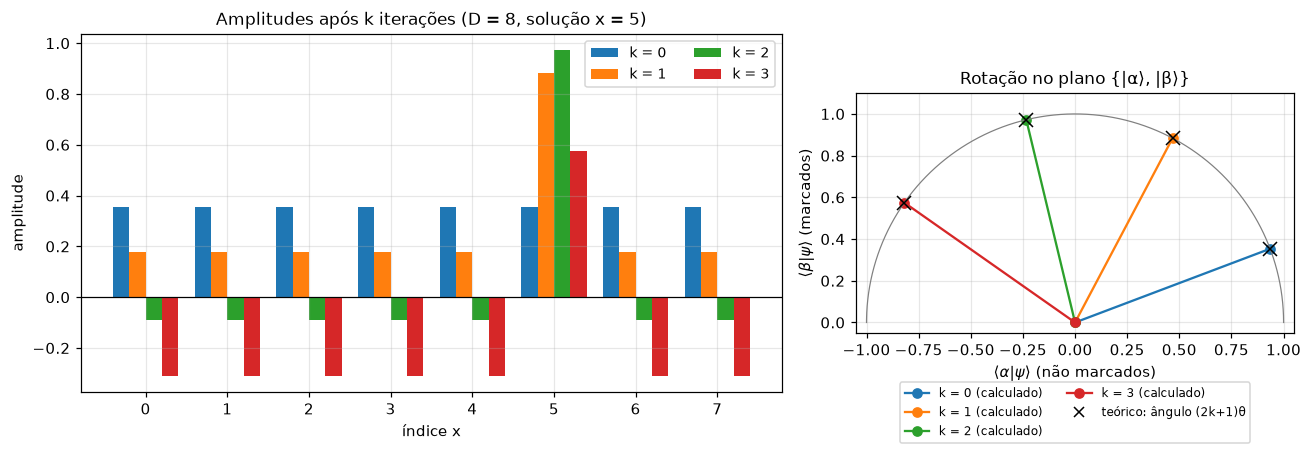

In [ ]:
def coordenadas_plano(psi: np.ndarray, marcados: Sequence[int]) -> tuple[float, float]:
    """Projeções de psi sobre |alpha> (não marcados) e |beta> (marcados)."""
    D = len(psi)
    mascara = np.zeros(D, dtype=bool)
    mascara[list(marcados)] = True
    beta = psi[mascara].real.sum() / math.sqrt(mascara.sum())
    alfa = psi[~mascara].real.sum() / math.sqrt((~mascara).sum())
    return alfa, beta


def grafico_amplitudes_grover(n: int, marcados: tuple, k_max: int) -> plt.Figure:
    D = 2**n
    theta = angulo_grover(len(marcados), D)
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
    largura = 0.8 / (k_max + 1)
    for k in range(k_max + 1):
        psi = grover_estado(n, marcados, k)
        eixos[0].bar(np.arange(D) + k * largura - 0.4 + largura / 2, psi.real, width=largura, label=f"k = {k}")
        a, b = coordenadas_plano(psi, marcados)
        eixos[1].plot([0, a], [0, b], "-o", label=f"k = {k} (calculado)")
    eixos[0].axhline(0, color="black", lw=0.8)
    eixos[0].set(xlabel="índice x", ylabel="amplitude", xticks=range(D),
                title=f"Amplitudes após k iterações (D = {D}, solução x = {marcados[0]})")
    eixos[0].legend(ncol=2)
    angulos = np.linspace(0, math.pi, 200)
    eixos[1].plot(np.cos(angulos), np.sin(angulos), color="gray", lw=0.8)
    for k in range(k_max + 1):
        ang = (2 * k + 1) * theta
        eixos[1].plot(math.cos(ang), math.sin(ang), "kx", ms=9)
    eixos[1].plot([], [], "kx", label="teórico: ângulo (2k+1)θ")
    eixos[1].set(xlabel=r"$\langle\alpha|\psi\rangle$ (não marcados)",
                ylabel=r"$\langle\beta|\psi\rangle$ (marcados)",
                title="Rotação no plano {|α⟩, |β⟩}", aspect="equal", xlim=(-1.05, 1.05), ylim=(-0.05, 1.1))
    eixos[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)
    fig.tight_layout()
    return fig


fig = grafico_amplitudes_grover(3, (5,), 3)
salvar_figura(fig, "grover_amplitudes_geometria")
plt.show()

#### Probabilidade de sucesso em função de $k$ e efeito de iterar demais (Problema do Sufflê)

Compara três quantidades para $D = 64$ e $M = 1$. A probabilidade exata obtida do circuito, a frequência com shots e a curva teórica $\sin^2((2k+1)\theta)$. Também usa-se $N = 12$, que não é potência de dois, codificado em $D = 16$ com a solução $x = 7$. Nesse caso, mostra a probabilidade de medir um índice inválido.

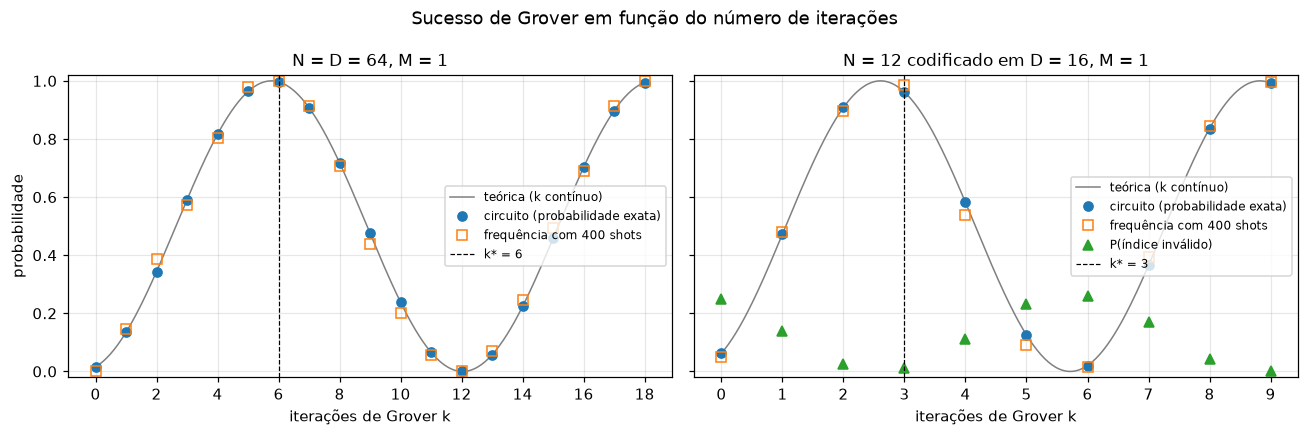

,k,P(sucesso) circuito,P(inválido) circuito,frequência amostrada,P teórica
0,0,0.0625,0.2500,0.0500,0.0625
1,1,0.4727,0.1406,0.4800,0.4727
2,2,0.9084,0.0244,0.8950,0.9084
3,3,0.9613,0.0103,0.9850,0.9613
4,4,0.5817,0.1115,0.5375,0.5817
5,5,0.1255,0.2332,0.0900,0.1255
6,6,0.0204,0.2612,0.0150,0.0204
7,7,0.3649,0.1694,0.3925,0.3649
8,8,0.8361,0.0437,0.8450,0.8361
9,9,0.9922,0.0021,0.9975,0.9922


In [ ]:
def curva_sucesso_grover(n: int, marcados: tuple, N_valido: int, k_max: int, shots: int) -> pd.DataFrame:
    amostrador = qml.set_shots(grover_amostra, shots=shots)
    linhas = []
    for k in range(k_max + 1):
        p = grover_probabilidades(n, marcados, k)
        amostras = np.atleast_2d(amostrador(n, marcados, k))
        indices = np.array([bits_para_inteiro(a) for a in amostras])
        linhas.append({
            "k": k,
            "P(sucesso) circuito": float(p[list(marcados)].sum()),
            "P(inválido) circuito": float(p[N_valido:].sum()),
            "frequência amostrada": float(np.isin(indices, marcados).mean()),
            "P teórica": float(prob_teorica_grover(k, len(marcados), 2**n)),
        })
    return pd.DataFrame(linhas)


shots_freq = CONFIG["grover_shots_frequencia"]
curva_64 = curva_sucesso_grover(6, (42,), 64, 3 * iteracoes_otimas(1, 64), shots_freq)
curva_12 = curva_sucesso_grover(4, (7,), 12, 3 * iteracoes_otimas(1, 16), shots_freq)
verificar("Grover: P(sucesso) do circuito = sin^2((2k+1)θ), D=64",
          np.allclose(curva_64["P(sucesso) circuito"], curva_64["P teórica"], atol=1e-9))
verificar("Grover: P(sucesso) do circuito = sin^2((2k+1)θ) com D=16 para N=12",
          np.allclose(curva_12["P(sucesso) circuito"], curva_12["P teórica"], atol=1e-9))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for eixo, curva, titulo, kopt in [
    (eixos[0], curva_64, "N = D = 64, M = 1", iteracoes_otimas(1, 64)),
    (eixos[1], curva_12, "N = 12 codificado em D = 16, M = 1", iteracoes_otimas(1, 16)),
]:
    kk = np.linspace(0, curva["k"].max(), 300)
    D = 64 if eixo is eixos[0] else 16
    eixo.plot(kk, prob_teorica_grover(kk, 1, D), color="gray", lw=1, label="teórica (k contínuo)")
    eixo.plot(curva["k"], curva["P(sucesso) circuito"], "o", label="circuito (probabilidade exata)")
    eixo.plot(curva["k"], curva["frequência amostrada"], "s", mfc="none",
              label=f"frequência com {shots_freq} shots")
    if eixo is eixos[1]:
        eixo.plot(curva["k"], curva["P(inválido) circuito"], "^", label="P(índice inválido)")
    eixo.axvline(kopt, ls="--", color="black", lw=0.8, label=f"k* = {kopt}")
    eixo.set(xlabel="iterações de Grover k", title=titulo, ylim=(-0.02, 1.02))
    eixo.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    eixo.legend(fontsize=8)
eixos[0].set_ylabel("probabilidade")
fig.suptitle("Sucesso de Grover em função do número de iterações")
fig.tight_layout()
salvar_figura(fig, "grover_sucesso_vs_iteracoes")
plt.show()
curva_12.round(4)

#### Rotina de busca com número de soluções conhecido

A rotina aplica $k^*$ iterações, mede um shot e verifica o candidato com uma consulta clássica. Se a verificação falhar, a rotina repete. O custo por tentativa é $k^*$ consultas a $O_f$ mais uma consulta de verificação. O número esperado de consultas é $(k^*+1)/P(k^*)$. Esta rotina usa o valor de $M$ para escolher $k^*$.

In [ ]:
@dataclass
class ResultadoBuscaQuantica:
    indice: int | None
    consultas_oraculo: int
    consultas_verificacao: int
    execucoes_circuito: int

    @property
    def consultas_totais(self) -> int:
        return self.consultas_oraculo + self.consultas_verificacao


def busca_grover_M_conhecido(N: int, marcados: tuple, M: int, max_tentativas: int = 50) -> ResultadoBuscaQuantica:
    n = qubits_necessarios(N)
    k = iteracoes_otimas(M, 2**n)
    predicado = criar_predicado(marcados)
    oraculo, verif = 0, 0
    
    for tentativa in range(1, max_tentativas + 1):
        x = medir_indice(grover_amostra(n, marcados, k))
        oraculo += k
        verif += 1
        if x < N and predicado(x):
            return ResultadoBuscaQuantica(x, oraculo, verif, tentativa)
    return ResultadoBuscaQuantica(None, oraculo, verif, max_tentativas)


def varredura_grover_vs_classica(qubits: Sequence[int], n_execucoes: int, rng: np.random.Generator) -> pd.DataFrame:
    linhas = []
    
    for n in qubits:
        N = 2**n
        consultas_q, consultas_c = [], []
        t0 = time.perf_counter()
        
        for _ in range(n_execucoes):
            alvo = int(rng.integers(N))
            r = busca_grover_M_conhecido(N, (alvo,), 1)
            if r.indice != alvo:
                raise RuntimeError("busca de Grover não encontrou o alvo dentro do limite de tentativas")
            consultas_q.append(r.consultas_totais)
        t_sim = (time.perf_counter() - t0) / n_execucoes
        
        for _ in range(n_execucoes):
            alvo = int(rng.integers(N))
            consultas_c.append(busca_aleatoria_sem_reposicao(N, criar_predicado([alvo]), rng).consultas)
        k = iteracoes_otimas(1, N)
        linhas.append({
            "n qubits": n, "N": N, "k*": k,
            "Grover: consultas médias": np.mean(consultas_q),
            "Grover: esperado (k*+1)/P(k*)": (k + 1) / prob_teorica_grover(k, 1, N),
            "clássica: consultas médias": np.mean(consultas_c),
            "clássica: esperado (N+1)/2": (N + 1) / 2,
            "tempo de simulação por busca (ms)": 1e3 * t_sim,
        })
    return pd.DataFrame(linhas)


rng_grover = np.random.default_rng(SEMENTE + 2)
tabela_grover = varredura_grover_vs_classica(CONFIG["grover_qubits"], CONFIG["grover_execucoes"], rng_grover)
salvar_tabela(tabela_grover, "grover_vs_classica")
tabela_grover.round(3)

,n qubits,N,k*,Grover: consultas médias,Grover: esperado (k*+1)/P(k*),clássica: consultas médias,clássica: esperado (N+1)/2,tempo de simulação por busca (ms)
0,2,4,1,2.000,2.000,2.380,2.5,2.432
1,3,8,2,3.105,3.174,4.305,4.5,2.984
2,4,16,3,4.100,4.161,8.610,8.5,3.922
3,5,32,4,5.000,5.004,16.700,16.5,3.789
4,6,64,6,7.035,7.024,34.220,32.5,7.212
5,7,128,8,9.000,9.040,64.535,64.5,10.453
6,8,256,12,13.000,13.001,124.215,128.5,29.678


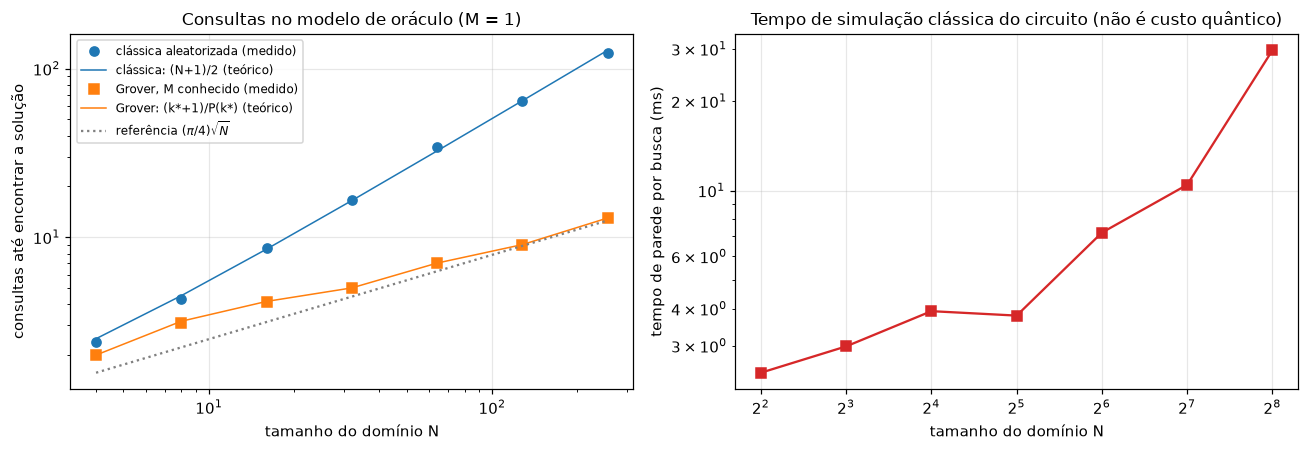

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2))
N_vals = tabela_grover["N"].to_numpy()
eixos[0].loglog(N_vals, tabela_grover["clássica: consultas médias"], "o", label="clássica aleatorizada (medido)")
eixos[0].loglog(N_vals, tabela_grover["clássica: esperado (N+1)/2"], "-", color="C0", lw=1, label="clássica: (N+1)/2 (teórico)")
eixos[0].loglog(N_vals, tabela_grover["Grover: consultas médias"], "s", label="Grover, M conhecido (medido)")
eixos[0].loglog(N_vals, tabela_grover["Grover: esperado (k*+1)/P(k*)"], "-", color="C1", lw=1, label="Grover: (k*+1)/P(k*) (teórico)")
eixos[0].loglog(N_vals, (math.pi / 4) * np.sqrt(N_vals), ":", color="gray", label=r"referência $(\pi/4)\sqrt{N}$")
eixos[0].set(xlabel="tamanho do domínio N", ylabel="consultas até encontrar a solução", title="Consultas no modelo de oráculo (M = 1)")
eixos[0].legend(fontsize=8)
eixos[1].semilogy(N_vals, tabela_grover["tempo de simulação por busca (ms)"], "s-", color="C3")
eixos[1].set_xscale("log", base=2)
eixos[1].set(xlabel="tamanho do domínio N", ylabel="tempo de parede por busca (ms)", title="Tempo de simulação clássica do circuito (não é custo quântico)")
fig.tight_layout()
salvar_figura(fig, "grover_consultas_e_tempo")
plt.show()

#### Busca com número de soluções desconhecido (BBHT)

Quando $M$ é desconhecido, não é possível escolher $k^*$. O algoritmo de BBHT contorna essa limitação:

1. Inicializa $m = 1$ e escolhe $\lambda = 6/5$. Os autores admitem qualquer $1 < \lambda < 4/3$.
2. Sorteie $j$ uniformemente em $\{0, 1, \dots, \lceil m\rceil - 1\}$.
3. Aplique $j$ iterações de Grover, meça e verifique o candidato.
4. Se for solução, pare. Caso contrário, faça $m \leftarrow \min(\lambda m, \sqrt{D})$ e volte ao passo 2.

O limite $m$ cresce geometricamente. Para $m \geq 1/\sin 2\theta$, a probabilidade média de sucesso de uma rodada é pelo menos $1/4$. O Teorema 3 limita o número esperado de iterações por $\tfrac{9}{2}m_0$, com $m_0 = 1/\sin 2\theta < \sqrt{D/M}$. Quando $M = 0$, o algoritmo não termina sozinho. Por isso, adotamos um orçamento máximo de consultas, declarado abaixo, e a resposta "sem solução" passa a ter uma probabilidade pequena de erro.

In [ ]:
@dataclass
class ResultadoBBHT:
    indice: int | None
    consultas_oraculo: int
    consultas_verificacao: int
    rodadas: int

    @property
    def consultas_totais(self) -> int:
        return self.consultas_oraculo + self.consultas_verificacao


def bbht(N: int, marcados: tuple, rng: np.random.Generator, lam: float = 6 / 5, orcamento: int | None = None) -> ResultadoBBHT:
    """Busca com M desconhecido. `marcados` define apenas o oráculo; o algoritmo não usa M."""
    n = qubits_necessarios(N)
    D = 2**n
    predicado = criar_predicado(marcados)
    m, oraculo, verif, rodadas = 1.0, 0, 0, 0
    
    while True:
        j = int(rng.integers(0, math.ceil(m)))
        if orcamento is not None and oraculo + verif + j + 1 > orcamento:
            return ResultadoBBHT(None, oraculo, verif, rodadas)
        x = medir_indice(grover_amostra(n, marcados, j))
        oraculo, verif, rodadas = oraculo + j, verif + 1, rodadas + 1
        if x < N and predicado(x):
            return ResultadoBBHT(x, oraculo, verif, rodadas)
        m = min(lam * m, math.sqrt(D))


def experimento_bbht(N: int, valores_M: Sequence[int], n_execucoes: int, rng: np.random.Generator) -> pd.DataFrame:
    D = 2 ** qubits_necessarios(N)
    linhas = []
    
    for M in valores_M:
        consultas = []
        
        for _ in range(n_execucoes):
            marcados = tuple(int(x) for x in rng.choice(N, size=M, replace=False))
            r = bbht(N, marcados, rng)
            consultas.append((r.consultas_oraculo, r.consultas_totais))
        consultas = np.array(consultas)
        theta = angulo_grover(M, D)
        k = iteracoes_otimas(M, D)
        linhas.append({
            "M": M,
            "BBHT: iterações de Grover médias": consultas[:, 0].mean(),
            "BBHT: consultas totais médias": consultas[:, 1].mean(),
            "cota de iterações (9/2)/sin 2θ": 4.5 / math.sin(2 * theta),
            "M conhecido: (k*+1)/P(k*)": (k + 1) / prob_teorica_grover(k, M, D)})
    return pd.DataFrame(linhas)


rng_bbht = np.random.default_rng(SEMENTE + 3)
N_bbht = CONFIG["bbht_N"]
tabela_bbht = experimento_bbht(N_bbht, CONFIG["bbht_M"], CONFIG["bbht_execucoes"], rng_bbht)
salvar_tabela(tabela_bbht, "bbht_M_desconhecido")

# Caso sem solução
orcamento_bbht = int(math.ceil(9 * math.sqrt(N_bbht)))
sem_solucao = [bbht(N_bbht, tuple(), rng_bbht, orcamento=orcamento_bbht) for _ in range(20)]
verificar("BBHT com M = 0 termina por orçamento sem excedê-lo", all(r.indice is None and r.consultas_totais <= orcamento_bbht for r in sem_solucao))
print(f"M = 0: 20 execuções terminaram sem solução, com no máximo {orcamento_bbht} consultas " f"(orçamento escolhido como 9·sqrt(N), constante didática).")
tabela_bbht.round(2)

M = 0: 20 execuções terminaram sem solução, com no máximo 72 consultas (orçamento escolhido como 9·sqrt(N), constante didática).


,M,BBHT: iterações de Grover médias,BBHT: consultas totais médias,cota de iterações (9/2)/sin 2θ,M conhecido: (k*+1)/P(k*)
0,1,5.51,12.41,18.14,7.02
1,2,3.22,8.35,12.93,5.00
2,4,2.05,6.07,9.30,4.16
3,8,0.94,3.77,6.80,3.17
4,16,0.65,2.80,5.20,2.00


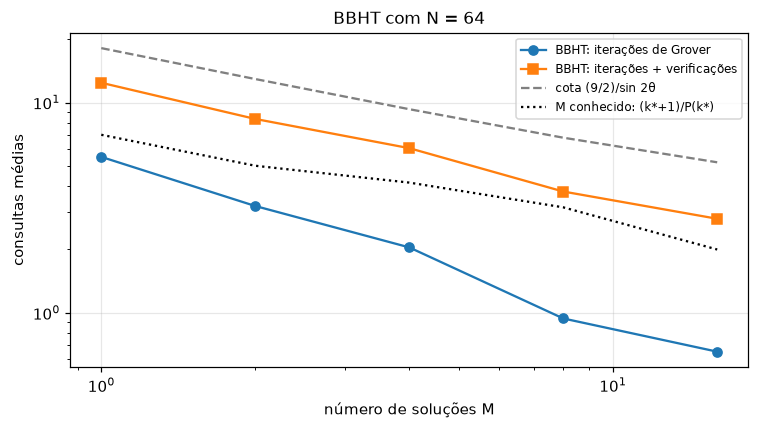

In [ ]:
fig, eixo = plt.subplots(figsize=(7, 4))
eixo.loglog(tabela_bbht["M"], tabela_bbht["BBHT: iterações de Grover médias"], "o-", label="BBHT: iterações de Grover")
eixo.loglog(tabela_bbht["M"], tabela_bbht["BBHT: consultas totais médias"], "s-", label="BBHT: iterações + verificações")
eixo.loglog(tabela_bbht["M"], tabela_bbht["cota de iterações (9/2)/sin 2θ"], "--", color="gray", label="cota (9/2)/sin 2θ")
eixo.loglog(tabela_bbht["M"], tabela_bbht["M conhecido: (k*+1)/P(k*)"], ":", color="black", label="M conhecido: (k*+1)/P(k*)")
eixo.set(xlabel="número de soluções M", ylabel="consultas médias", title=f"BBHT com N = {N_bbht}")
eixo.legend(fontsize=8)
fig.tight_layout()
salvar_figura(fig, "bbht_consultas_vs_M")
plt.show()

<a id="sec-2"></a>
## 2. Busca de mínimos por Dürr e Høyer

### 2.1 Problema e hipóteses

Dada uma lista de custos inteiros $T[0], \dots, T[N-1]$, queremos o índice do valor mínimo. Cada leitura de $T[i]$ é uma consulta. Classicamente, sem estrutura, são necessárias $N$ leituras para garantir o mínimo.

**Empates.** Usamos a ordem lexicográfica entre os pares $(T[i], i)$. O índice $i$ é melhor que o pivô $y$ quando:

$$(T[i], i) < (T[y], y) \iff T[i] < T[y] \ \text{ou}\ \big(T[i] = T[y] \text{ e } i < y\big).$$

Essa ordem é total. Por isso, o mínimo lexicográfico é único, mesmo quando há custos repetidos.

**Representação binária.** Os custos usam $b$ bits, com $0 \le T[i] < 2^b$. Os índices usam $n = \lceil \log_2 N \rceil$ qubits. Os índices $i \geq N$ são inválidos. Eles não recebem custo nenhum, em particular não recebem custo zero, nunca são marcados como melhores, e sua medição conta como falha.

### 2.2 Ideia do método

O algoritmo de Dürr e Høyer mantém um pivô $y$, sorteado inicialmente de forma uniforme, e repete:

1. Marca todos os índices melhores que $y$ com o oráculo de fase dependendo de $y$.
2. Executa a busca exponencial BBHT sobre os marcados.
3. Mede um candidato $y'$, consulta $T[y']$ e, se $y'$ for melhor, faz $y \leftarrow y'$.

Quando o pivô muda, o conjunto marcado muda e a BBHT é reiniciada, com $m = 1$. A BBHT não usa o número verdadeiro de candidatos melhores. Os índices não marcados continuam na superposição, e a medição pode devolver um índice não melhor, que é descartado após a verificação.

### 2.3 Exemplo reduzido de oráculo reversível

Antes do oráculo idealizado, construímos um oráculo reversível completo para $N = 4$, com custos de $b = 2$ bits. Os registradores são:

- índice: 2 qubits (`w_idx`);
- custo: 2 qubits auxiliares, inicialmente $|00\rangle$ (`w_custo`);
- sinalizador: 1 qubit em $|-\rangle$ (`w_flag`), que converte a inversão do sinalizador em fase $-1$ (retrocesso de fase).

As etapas são:

1. **Carregamento:** $|i\rangle|0\rangle \mapsto |i\rangle|T[i]\rangle$, com portas X multicontroladas pelo índice. Isso reproduz uma tabela de consulta, e o número de portas cresce com $N\,b$.
2. **Comparação com o limiar:** o sinalizador é invertido se $(T[i], i) < (T[y], y)$. Como o pivô é um dado clássico do circuito, a comparação é compilada como uma união de padrões disjuntos: custo $v < T[y]$, ou custo $= T[y]$ com índice $< y$.
3. **Desfazimento:** o carregamento é repetido. Como ele é uma operação XOR, o registrador de custo volta a $|00\rangle$.

O resultado líquido no registrador de índice é $|i\rangle \mapsto (-1)^{[i \text{ melhor que } y]}|i\rangle$, com os auxiliares restaurados. O código abaixo verifica essa propriedade para todos os índices e pivôs da instância.

In [ ]:
def carregar_custos(custos: Sequence[int], w_idx: list[int], w_custo: list[int], b: int) -> None:
    """|i>|c> -> |i>|c XOR T[i]> por portas X multicontrolada."""
    n = len(w_idx)
    for i, c in enumerate(custos):
        for pos, bit in enumerate(inteiro_para_bits(int(c), b)):
            if bit:
                qml.MultiControlledX(wires=w_idx + [w_custo[pos]], control_values=inteiro_para_bits(i, n))


def comparar_com_pivo(custo_pivo: int, indice_pivo: int, w_idx: list[int], w_custo: list[int], w_flag: int, b: int) -> None:
    """Inverte o sinalizador se (custo, índice) < (custo_pivo, indice_pivo)."""
    n = len(w_idx)
    for v in range(custo_pivo):  # custo estritamente menor
        qml.MultiControlledX(wires=w_custo + [w_flag], control_values=inteiro_para_bits(v, b))
    for i in range(indice_pivo):  # empate no custo e índice menor
        qml.MultiControlledX(wires=w_custo + w_idx + [w_flag],
                             control_values=inteiro_para_bits(custo_pivo, b) + inteiro_para_bits(i, n))


def oraculo_reversivel_custos(custos: Sequence[int], pivo: int, w_idx: list[int], w_custo: list[int], w_flag: int, b: int) -> None:
    carregar_custos(custos, w_idx, w_custo, b)
    comparar_com_pivo(int(custos[pivo]), pivo, w_idx, w_custo, w_flag, b)
    carregar_custos(custos, w_idx, w_custo, b)


CUSTOS_EXEMPLO = (2, 1, 3, 1)  # empate de custo entre os índices 1 e 3
B_EXEMPLO = 2
W_IDX, W_CUSTO, W_FLAG = [0, 1], [2, 3], 4


@qml.qnode(DEV, diff_method=None)
def estado_oraculo_reversivel(indice: int, pivo: int):
    qml.BasisState(np.array(inteiro_para_bits(indice, 2)), wires=W_IDX)
    qml.PauliX(W_FLAG)
    qml.Hadamard(W_FLAG)
    oraculo_reversivel_custos(CUSTOS_EXEMPLO, pivo, W_IDX, W_CUSTO, W_FLAG, B_EXEMPLO)
    return qml.state()


def melhor_que(custos: Sequence[int], i: int, j: int) -> bool:
    """(T[i], i) < (T[j], j) na ordem lexicográfica."""
    return (custos[i], i) < (custos[j], j)


def estado_esperado_oraculo(indice: int, sinal: int) -> np.ndarray:
    """sinal * |indice>|00>|->, na ordem de fios (idx0, idx1, custo0, custo1, flag)."""
    menos = np.array([1, -1]) / math.sqrt(2)
    base_idx = np.zeros(4); base_idx[indice] = 1
    base_custo = np.zeros(4); base_custo[0] = 1
    return sinal * np.kron(np.kron(base_idx, base_custo), menos)

linhas = []

for pivo in range(4):
    
    for i in range(4):
        sinal = -1 if melhor_que(CUSTOS_EXEMPLO, i, pivo) else 1
        ok = np.allclose(estado_oraculo_reversivel(i, pivo), estado_esperado_oraculo(i, sinal), atol=TOL)
        verificar(f"oráculo reversível: pivô {pivo}, índice {i}", ok)
        linhas.append({"pivô y": pivo, "T[y]": CUSTOS_EXEMPLO[pivo], "índice i": i, "T[i]": CUSTOS_EXEMPLO[i], "fase aplicada": sinal, "auxiliares restaurados": ok})

tabela_oraculo = pd.DataFrame(linhas)
salvar_tabela(tabela_oraculo, "oraculo_reversivel_exemplo")
print("Circuito do oráculo reversível para o pivô y = 0:")
print(qml.draw(oraculo_reversivel_custos, wire_order=W_IDX + W_CUSTO + [W_FLAG])(CUSTOS_EXEMPLO, 0, W_IDX, W_CUSTO, W_FLAG, B_EXEMPLO))
tabela_oraculo.pivot(index="índice i", columns="pivô y", values="fase aplicada")

Circuito do oráculo reversível para o pivô y = 0:
0: ─╭○─╭○─╭●─╭●─╭●───────╭○─╭○─╭●─╭●─╭●─┤  
1: ─├○─├●─├○─├○─├●───────├○─├●─├○─├○─├●─┤  
2: ─╰X─│──╰X─│──│──╭○─╭○─╰X─│──╰X─│──│──┤  
3: ────╰X────╰X─╰X─├○─├●────╰X────╰X─╰X─┤  
4: ────────────────╰X─╰X────────────────┤  


pivô y,0,1,2,3
índice i,,,,
0,1,1,-1,1
1,-1,1,-1,-1
2,1,1,1,1
3,-1,1,-1,1


A tabela mostra a fase aplicada a cada índice $i$ para cada pivô $y$. Com $y = 1$, cujo custo é 1, o índice 3 tem o mesmo custo, mas não é marcado, porque $3 > 1$ na ordem de desempate. O índice 1 é o mínimo lexicográfico e, com ele como pivô, nenhum índice é marcado.

### 2.4 Oráculo idealizado para as instâncias experimentais

Nas instâncias maiores, usamos um oráculo de fase idealizado, `qml.DiagonalQubitUnitary`, com diagonal $(-1)^{[i \text{ melhor que } y]}$ e $+1$ nos índices inválidos. Para montar essa diagonal, o programa lê a tabela inteira, um custo clássico $O(N)$ por pivô. Essa montagem não é uma consulta de caixa-preta e não é contada como tal. Cada aplicação do operador conta como uma consulta ao oráculo, como no exemplo reversível. Para o exemplo reduzido, verificamos abaixo que as duas construções coincidem no registrador de índice.

In [ ]:
def diagonal_oraculo_ideal(custos: Sequence[int], pivo: int, D: int) -> np.ndarray:
    """Diagonal +-1 do oráculo idealizado. Índices inválidos (>= N) nunca são marcados."""
    diag = np.ones(D)
    for i in range(len(custos)):
        if melhor_que(custos, i, pivo):
            diag[i] = -1.0
    return diag


for pivo in range(4):
    diag = diagonal_oraculo_ideal(CUSTOS_EXEMPLO, pivo, 4)
    fases = tabela_oraculo.query("`pivô y` == @pivo")["fase aplicada"].to_numpy()
    verificar(f"oráculo idealizado = oráculo reversível (pivô {pivo})", np.array_equal(diag, fases))


@qml.set_shots(1)
@qml.qnode(DEV, diff_method=None)
def amostra_grover_diagonal(n: int, diag: np.ndarray, j: int):
    wires = list(range(n))
    preparar_superposicao(wires)
    for _ in range(j):
        qml.DiagonalQubitUnitary(diag, wires=wires)
        difusor(wires)
    return qml.sample(wires=wires)

### 2.5 Implementação, contagem de consultas e orçamento

**Operações contadas.** Uma iteração de Grover conta como uma consulta ao oráculo. Cada medição gera uma leitura clássica de $T[y']$, contada como uma consulta de verificação. A leitura de $T[y]$ do pivô inicial também conta. A construção da diagonal idealizada não é contada como consulta, como explicado acima.

**Orçamento e probabilidade de sucesso.** Dürr e Høyer (Lema 2) mostram que o tempo esperado até o pivô conter o mínimo é no máximo

$$m_0 = \tfrac{45}{4}\sqrt N + \tfrac{7}{10}\log_2^2 N.$$

Nessa contagem, cada rodada custa $\log_2 N$ passos de preparação, mais as iterações de Grover. Na nossa contagem, cada rodada custa as iterações mais uma verificação. Como $1 \le \log_2 N$ para $N \ge 2$, o custo de cada trajetória na nossa contagem nunca excede o custo da mesma trajetória na contagem do artigo. Pela desigualdade de Markov, a probabilidade de o tempo até o mínimo exceder $2m_0$ é no máximo $1/2$. Adotamos, portanto, o orçamento global $B = \lceil 2 m_0 \rceil$ consultas. Com ele, cada execução retorna o mínimo com probabilidade pelo menos $1/2$, mesmo com custos repetidos, que o artigo trata com $p(t,r) \le 1/r$.

Essa garantia decorre da análise. A constante 2 vem da desigualdade de Markov e não foi ajustada experimentalmente.

**Duas grandezas distintas.**

- $T_{\min}$: consultas acumuladas até o pivô se tornar o mínimo. É aleatória e usada na análise. Calculamos esse valor **depois** da execução, comparando o histórico de pivôs com o mínimo verdadeiro. O algoritmo não tem acesso a ele.
- $B$: orçamento que o programa observa e respeita. Ele termina mesmo quando o pivô já é o mínimo e nenhum índice é marcado.

**Repetição.** Executar $r$ vezes de forma independente e devolver o melhor resultado verificado reduz a probabilidade de erro para no máximo $2^{-r}$.

In [ ]:
@dataclass
class ResultadoDH:
    indice: int
    consultas: int
    orcamento: int
    historico: list[dict]  # atualizações do pivô


def orcamento_durr_hoyer(N: int) -> int:
    m0 = 45 / 4 * math.sqrt(N) + 7 / 10 * math.log2(N) ** 2
    return int(math.ceil(2 * m0))


def durr_hoyer(custos: Sequence[int], rng: np.random.Generator, lam: float = 6 / 5, orcamento: int | None = None, pivo_inicial: int | None = None) -> ResultadoDH:
    """Busca de mínimo (ordem lexicográfica custo, índice) com BBHT reiniciada a cada melhoria."""
    
    N = len(custos)
    n = qubits_necessarios(N)
    D = 2**n
    B = orcamento_durr_hoyer(N) if orcamento is None else orcamento
    y = int(rng.integers(N)) if pivo_inicial is None else pivo_inicial
    consultas = 1  # leitura de T[y]
    historico = [{"consultas": consultas, "pivô": y, "custo": int(custos[y])}]
    diag = diagonal_oraculo_ideal(custos, y, D)
    m = 1.0
    
    while True:
        
        j = int(rng.integers(0, math.ceil(m)))
        if consultas + j + 1 > B:
            break
        x = medir_indice(amostra_grover_diagonal(n, diag, j))
        consultas += j + 1  # j consultas ao oráculo + 1 leitura de T[x]
        if x < N and melhor_que(custos, x, y):
            y = x
            historico.append({"consultas": consultas, "pivô": y, "custo": int(custos[y])})
            diag = diagonal_oraculo_ideal(custos, y, D)
            m = 1.0  # reinício da BBHT
        else:
            m = min(lam * m, math.sqrt(D))
    return ResultadoDH(y, consultas, B, historico)


def durr_hoyer_repetido(custos: Sequence[int], rng: np.random.Generator, r: int) -> tuple[int, int]:
    """Executa r execuções independentes e devolve o melhor índice verificado e as consultas totais."""
    resultados = [durr_hoyer(custos, rng) for _ in range(r)]
    melhor = min((res.indice for res in resultados), key=lambda i: (custos[i], i))
    return melhor, sum(res.consultas for res in resultados)


def indice_minimo_lexicografico(custos: Sequence[int]) -> int:
    """Mínimo verdadeiro, usado apenas para validar resultados."""
    return min(range(len(custos)), key=lambda i: (custos[i], i))


def consultas_ate_minimo(resultado: ResultadoDH, indice_min: int) -> int | None:
    """T_min calculado após a execução (análise); None se o mínimo não foi alcançado."""
    
    for registro in resultado.historico:
        if registro["pivô"] == indice_min:
            return registro["consultas"]
    return None


def busca_minimo_classica(custos: Sequence[int]) -> tuple[int, int]:
    return indice_minimo_lexicografico(custos), len(custos)

### 2.6 Testes de casos especiais

Os testes cobrem quatro situações: todos os custos iguais, em que o mínimo lexicográfico é o índice 0; tamanho que não é potência de dois; pivô inicial já mínimo, sem melhoria possível; e respeito ao orçamento.

In [ ]:
rng_dh_teste = np.random.default_rng(SEMENTE + 4)

custos_empate = [5] * 12
res = durr_hoyer(custos_empate, rng_dh_teste)
verificar("DH: custos todos iguais, resultado é melhor ou igual ao pivô e orçamento respeitado",
          res.consultas <= res.orcamento and res.indice <= res.historico[0]["pivô"])
# Com r = 3 repetições, a garantia é >= 7/8; exigir 20/40 torna a falha casual desprezível.
acertos = sum(durr_hoyer_repetido(custos_empate, rng_dh_teste, 3)[0] == 0 for _ in range(40))
verificar("DH: empates resolvidos pela ordem lexicográfica (mínimo = índice 0)",
          acertos >= 20, f"{acertos}/40 com r = 3")

custos_12 = [6, 3, 7, 3, 5, 1, 4, 1, 7, 2, 6, 5]  # N = 12, mínimo lexicográfico no índice 5
res = durr_hoyer(custos_12, rng_dh_teste, pivo_inicial=5)
verificar("DH: sem melhorias possíveis, mantém o pivô e termina pelo orçamento",
          res.indice == 5 and len(res.historico) == 1 and res.consultas <= res.orcamento)
verificar("DH: N = 12 (não potência de 2) usa D = 16 e índices inválidos nunca são marcados",
          np.all(diagonal_oraculo_ideal(custos_12, 0, 16)[12:] == 1))
orcamentos_ok = all(durr_hoyer(custos_12, rng_dh_teste, orcamento=b).consultas <= b for b in (1, 2, 5, 17, 40))
verificar("DH: consultas nunca excedem o orçamento", orcamentos_ok)
print(f"Testes de Dürr–Høyer aprovados. Empates: {acertos}/40 execuções (r = 3) retornaram o índice 0.")

Testes de Dürr–Høyer aprovados. Empates: 40/40 execuções (r = 3) retornaram o índice 0.


### 2.7 Resultados em uma instância com empates

A instância tem $N = 12$ e custos de $b = 3$ bits sorteados com semente fixa, de modo que haja custos repetidos. Primeiro mostramos a sequência de pivôs em algumas execuções. Depois, a frequência empírica de sucesso de uma execução e de $r = 3$ execuções repetidas.

custos = [0, 5, 4, 6, 3, 3, 0, 0, 0, 7, 2, 2]
mínimo lexicográfico (validação) = índice 0, custo 0
orçamento B = ceil(2 m0) = 96 consultas; busca clássica = 12 consultas


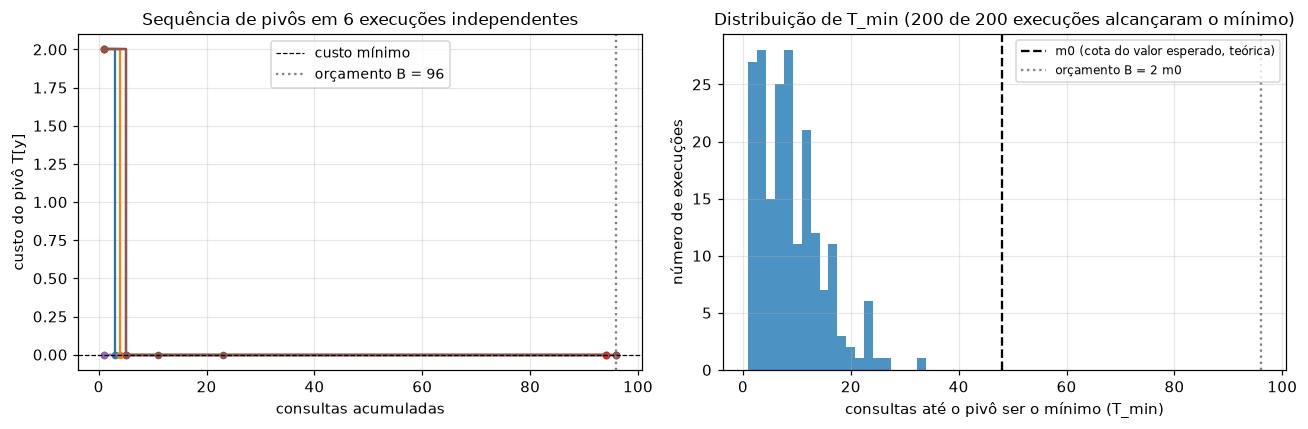

Frequência de sucesso, 1 execução : 1.000
Frequência de sucesso, r = 3      : 1.000


,consultas,pivô,custo
0,1,10,2
1,3,0,0


In [ ]:
rng_dh = np.random.default_rng(SEMENTE + 5)
N_dh, bits_dh = CONFIG["dh_N"], CONFIG["dh_bits"]
custos_dh = [int(c) for c in rng_dh.integers(0, 2**bits_dh, size=N_dh)]
indice_min_dh = indice_minimo_lexicografico(custos_dh)  # apenas para validação
B_dh = orcamento_durr_hoyer(N_dh)
print(f"custos = {custos_dh}")
print(f"mínimo lexicográfico (validação) = índice {indice_min_dh}, custo {custos_dh[indice_min_dh]}")
print(f"orçamento B = ceil(2 m0) = {B_dh} consultas; busca clássica = {N_dh} consultas")

execucoes = [durr_hoyer(custos_dh, rng_dh) for _ in range(CONFIG["dh_execucoes"])]
sucesso_1 = np.mean([e.indice == indice_min_dh for e in execucoes])
t_min = np.array([consultas_ate_minimo(e, indice_min_dh) or np.nan for e in execucoes], dtype=float)
repetidas = [durr_hoyer_repetido(custos_dh, rng_dh, 3) for _ in range(CONFIG["dh_execucoes"] // 3)]
sucesso_3 = np.mean([idx == indice_min_dh for idx, _ in repetidas])

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for e in execucoes[:6]:
    h = pd.DataFrame(e.historico)
    eixos[0].step(list(h["consultas"]) + [e.consultas], list(h["custo"]) + [h["custo"].iloc[-1]],
                  where="post", marker="o", ms=4)
eixos[0].axhline(custos_dh[indice_min_dh], ls="--", color="black", lw=0.8, label="custo mínimo")
eixos[0].axvline(B_dh, ls=":", color="gray", label=f"orçamento B = {B_dh}")
eixos[0].set(xlabel="consultas acumuladas", ylabel="custo do pivô T[y]",
             title="Sequência de pivôs em 6 execuções independentes")
eixos[0].legend()
validos = t_min[~np.isnan(t_min)]
eixos[1].hist(validos, bins=20, color="C0", alpha=0.8)
eixos[1].axvline(45 / 4 * math.sqrt(N_dh) + 0.7 * math.log2(N_dh) ** 2, color="black", ls="--",
                 label="m0 (cota do valor esperado, teórica)")
eixos[1].axvline(B_dh, color="gray", ls=":", label="orçamento B = 2 m0")
eixos[1].set(xlabel="consultas até o pivô ser o mínimo (T_min)", ylabel="número de execuções",
             title=f"Distribuição de T_min ({len(validos)} de {len(t_min)} execuções alcançaram o mínimo)")
eixos[1].legend(fontsize=8)
fig.tight_layout()
salvar_figura(fig, "durr_hoyer_pivos_e_tmin")
plt.show()

print(f"Frequência de sucesso, 1 execução : {sucesso_1:.3f}")
print(f"Frequência de sucesso, r = 3      : {sucesso_3:.3f}")
pd.DataFrame(execucoes[0].historico)

### 2.8 Comparação com a busca clássica do mínimo

A busca clássica do mínimo usa exatamente $N$ leituras. Para Dürr e Høyer, mostramos três grandezas: o orçamento $B = \lceil 2m_0\rceil$, que fornece a garantia de $1/2$; a média empírica de $T_{\min}$; e a frequência de sucesso.

Menor N com orçamento B < N: 741


KeyError: 'clássica'

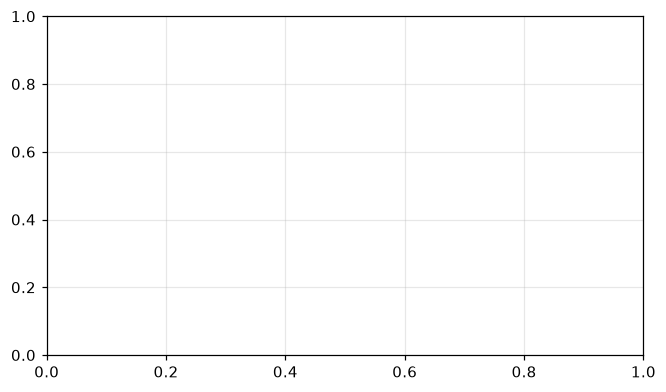

In [ ]:
def varredura_durr_hoyer(tamanhos: Sequence[int], n_execucoes: int, bits: int, rng: np.random.Generator) -> pd.DataFrame:
    linhas = []
    
    for N in tamanhos:
        sucessos, tmins = [], []
        
        for _ in range(n_execucoes):
            custos = [int(c) for c in rng.integers(0, 2**bits, size=N)]
            idx_min = indice_minimo_lexicografico(custos)
            e = durr_hoyer(custos, rng)
            sucessos.append(e.indice == idx_min)
            t = consultas_ate_minimo(e, idx_min)
            tmins.append(np.nan if t is None else t)
        linhas.append({"N": N, "clássica (consultas)": N, "DH: orçamento B": orcamento_durr_hoyer(N),
                       "DH: T_min médio (execuções com sucesso)": np.nanmean(tmins),
                       "DH: frequência de sucesso": np.mean(sucessos)})
    return pd.DataFrame(linhas)


tabela_dh = varredura_durr_hoyer(CONFIG["dh_tamanhos"], CONFIG["dh_execucoes_varredura"], 6, np.random.default_rng(SEMENTE + 6))
salvar_tabela(tabela_dh, "durr_hoyer_varredura")
N_cruzamento = next(N for N in range(2, 10**6) if orcamento_durr_hoyer(N) < N)
print(f"Menor N com orçamento B < N: {N_cruzamento}")

fig, eixo = plt.subplots(figsize=(7, 4))
eixo.loglog(tabela_dh["N"], tabela_dh["clássica"], "o-", label="clássica: N leituras")
eixo.loglog(tabela_dh["N"], tabela_dh["DH: orçamento B"], "s--", label="DH: orçamento B = ceil(2 m0)")
eixo.loglog(tabela_dh["N"], tabela_dh["DH: T_min médio"], "^-", label="DH: T_min médio (medido)")
eixo.set_xscale("log", base=2)
eixo.set(xlabel="tamanho da tabela N", ylabel="consultas", title="Busca do mínimo: custos em consultas")
eixo.legend(fontsize=8)
fig.tight_layout()
salvar_figura(fig, "durr_hoyer_vs_classica")
plt.show()
tabela_dh.round(3)

<a id="sec-3"></a>
## 3. Busca estruturada em espaços implícitos

### 3.1 Problema e hipóteses

Na busca estruturada, os candidatos são vértices de um grafo. O objetivo é encontrar uma solução partindo de um vértice inicial $s$ até o alvo $g$. Em IA, o grafo costuma ser implícito, isto é, não existe uma lista de vértices armazenada, mas uma função de sucessores que gera os vizinhos de um estado sob demanda.

O exemplo principal é o reticulado toroidal $L \times L$, com $L = 4$ por padrão:

- vértices $v = (x, y)$, com $x, y \in \{0, \dots, L-1\}$;
- quatro vizinhos por vértice, com condições periódicas: $(x \pm 1 \bmod L,\ y)$ e $(x,\ y \pm 1 \bmod L)$;
- codificação bijetiva $\operatorname{ind}(x, y) = xL + y$, com inversa $(\lfloor i/L\rfloor, i \bmod L)$.

**Direções e ordem dos sucessores.** As direções são numeradas e a função de sucessores devolve os vizinhos sempre nesta ordem:

| $d$ | Deslocamento | Nome | Inversa $d \oplus 1$ |
| --- | --- | --- | --- |
| 0 | $(+1, 0)$ | $+x$ | 1 |
| 1 | $(-1, 0)$ | $-x$ | 0 |
| 2 | $(0, +1)$ | $+y$ | 3 |
| 3 | $(0, -1)$ | $-y$ | 2 |

A mesma numeração define as portas da caminhada quântica na Seção 5. Para $L \geq 3$, os quatro vizinhos são distintos e não há laços.

**Métricas registradas.**

- **expansões:** estados retirados da fronteira e expandidos;
- **chamadas a `sucessores`;**
- **tamanho máximo da fronteira;**
- **estados armazenados ao final:** conjunto de visitados ou descobertos, mais a fronteira;
- **comprimento do caminho** e **sucesso**.

O teste de objetivo é feito quando o estado é retirado da fronteira, igualmente para BFS, DFS e A*.

In [ ]:
Vertice = tuple[int, int]

DIRECOES_TORO: tuple[tuple[int, int], ...] = ((+1, 0), (-1, 0), (0, +1), (0, -1))

def indice_vertice(v: Vertice, L: int) -> int:
    return v[0] * L + v[1]

def vertice_do_indice(i: int, L: int) -> Vertice:
    return divmod(i, L)

def criar_sucessores_toro(L: int) -> tuple[Callable[[Vertice], list[Vertice]], dict]:
    """Função de sucessores implícita do toro L x L e um contador de chamadas."""
    if L < 3:
        raise ValueError("L >= 3 garante quatro vizinhos distintos e ausência de laços.")
    contador = {"chamadas": 0}

    def sucessores(v: Vertice) -> list[Vertice]:
        contador["chamadas"] += 1
        x, y = v
        return [((x + dx) % L, (y + dy) % L) for dx, dy in DIRECOES_TORO]

    return sucessores, contador

def distancia_manhattan_toro(v: Vertice, alvo: Vertice, L: int) -> int:
    dx, dy = abs(v[0] - alvo[0]), abs(v[1] - alvo[1])
    return min(dx, L - dx) + min(dy, L - dy)

for L_teste in (3, 4, 5, 8):
    suc, _ = criar_sucessores_toro(L_teste)
    vertices = [vertice_do_indice(i, L_teste) for i in range(L_teste**2)]
    verificar(f"toro L={L_teste}: codificação bijetiva", all(indice_vertice(vertice_do_indice(i, L_teste), L_teste) == i for i in range(L_teste**2)))
    verificar(f"toro L={L_teste}: grau 4, sem laços, sem vizinhos repetidos", all(len(set(suc(v))) == 4 and v not in suc(v) for v in vertices))
    verificar(f"toro L={L_teste}: sucessores simétricos e inversa d^1", all(suc(suc(v)[d])[d ^ 1] == v for v in vertices for d in range(4)))

print("Função de sucessores do toro: grau, ausência de laços, simetria e inversas conferidos.")

### 3.2 Métodos

- **BFS** (busca em largura): fronteira FIFO. Explora por camadas de distância e, com custos unitários, encontra um caminho mínimo. Armazena todos os estados descobertos, cerca de $b^d$ para fator de ramificação $b$ e profundidade $d$.
- **DFS** (busca em profundidade): fronteira LIFO. Em uma árvore, pode manter apenas o caminho corrente e os irmãos pendentes, com memória linear na profundidade. Em um grafo com ciclos, como o toro, precisa de um conjunto de visitados para não repetir estados indefinidamente. Implementamos essa versão para grafos. O caminho é válido, mas não necessariamente mínimo.
- **A\***: fronteira ordenada por $f(v) = g(v) + h(v)$, em que $g$ é o custo acumulado e $h$ uma heurística. Com $h$ admissível ($h \le h^*$) e consistente, a busca em grafo encontra caminho ótimo sem reabrir estados. A heurística é a distância de Manhattan com contorno, $h(v) = \min(|\Delta x|, L - |\Delta x|) + \min(|\Delta y|, L - |\Delta y|)$. Cada passo altera uma única coordenada em $\pm 1 \bmod L$, de modo que $h$ diminui no máximo 1 por passo. Portanto, $h$ é consistente e admissível. No toro sem obstáculos, $h$ é exata. Desempate: menor $f$, depois menor $h$, depois ordem de inserção.
- **Passeio aleatório clássico**: a cada passo, escolhe um sucessor uniformemente, até atingir o objetivo ou esgotar um orçamento de passos. Não guarda estados, mas não oferece garantia de término nem de caminho curto.

A busca não depende de uma matriz de adjacência. A enumeração do grafo aparece apenas em funções separadas, para desenhar e construir operadores quânticos.

In [ ]:
@dataclass
class MetricasBusca:
    algoritmo: str
    sucesso: bool
    caminho: list[Vertice] | None
    expansoes: int
    chamadas_sucessores: int
    fronteira_max: int
    estados_armazenados: int
    ordem_expansao: list[Vertice] = field(default_factory=list)
    instantaneos_fronteira: list[list[Vertice]] = field(default_factory=list)

    def resumo(self) -> dict:
        return {"algoritmo": self.algoritmo, "sucesso": self.sucesso,
                "comprimento do caminho": None if self.caminho is None else len(self.caminho) - 1,
                "expansões": self.expansoes, "chamadas a sucessores": self.chamadas_sucessores,
                "fronteira máxima": self.fronteira_max, "estados armazenados": self.estados_armazenados}


def reconstruir_caminho(pais: dict, objetivo: Hashable) -> list:
    caminho = [objetivo]

    while pais[caminho[-1]] is not None:
        caminho.append(pais[caminho[-1]])

    return caminho[::-1]


def bfs(inicio: Vertice, objetivo: Vertice, sucessores: Callable, contador: dict, registrar: bool = False) -> MetricasBusca:
    c0 = contador["chamadas"]
    fronteira, pais = deque([inicio]), {inicio: None}
    expansoes, fronteira_max, ordem, inst = 0, 1, [], []

    while fronteira:
        v = fronteira.popleft()
        if v == objetivo:
            return MetricasBusca("BFS", True, reconstruir_caminho(pais, v), expansoes, contador["chamadas"] - c0, fronteira_max, len(pais), ordem, inst)
        expansoes += 1
        ordem.append(v)
        for u in sucessores(v):
            
            if u not in pais:
                pais[u] = v
                fronteira.append(u)
        fronteira_max = max(fronteira_max, len(fronteira))
        
        if registrar:
            inst.append(list(fronteira))

    return MetricasBusca("BFS", False, None, expansoes, contador["chamadas"] - c0, fronteira_max, len(pais), ordem, inst)


def dfs_grafo(inicio: Vertice, objetivo: Vertice, sucessores: Callable, contador: dict, registrar: bool = False) -> MetricasBusca:
    """DFS com conjunto de visitados."""
    c0 = contador["chamadas"]
    pilha, visitados, pais = [(inicio, None)], set(), {}
    expansoes, fronteira_max, ordem, inst = 0, 1, [], []

    while pilha:

        v, p = pilha.pop()
        if v in visitados:
            continue
        pais[v] = p
        if v == objetivo:
            return MetricasBusca("DFS", True, reconstruir_caminho(pais, v), expansoes, contador["chamadas"] - c0, fronteira_max, len(visitados) + len(pilha), ordem, inst)
        visitados.add(v)
        expansoes += 1
        ordem.append(v)

        for u in reversed(sucessores(v)):  # reversed: o primeiro sucessor é explorado primeiro
            if u not in visitados:
                pilha.append((u, v))

        fronteira_max = max(fronteira_max, len(pilha))
        if registrar:
            inst.append([u for u, _ in pilha if u not in visitados])

    return MetricasBusca("DFS", False, None, expansoes, contador["chamadas"] - c0, fronteira_max, len(visitados), ordem, inst)

def a_estrela(inicio: Vertice, objetivo: Vertice, sucessores: Callable, contador: dict, h: Callable[[Vertice], float], registrar: bool = False) -> MetricasBusca:
    c0 = contador["chamadas"]
    insercao = itertools.count()
    heap = [(h(inicio), h(inicio), next(insercao), inicio)]
    g, pais, fechados = {inicio: 0}, {inicio: None}, set()
    expansoes, fronteira_max, ordem, inst = 0, 1, [], []

    while heap:
        _, _, _, v = heapq.heappop(heap)
        if v in fechados:
            continue
        if v == objetivo:
            return MetricasBusca("A*", True, reconstruir_caminho(pais, v), expansoes, contador["chamadas"] - c0, fronteira_max, len(g), ordem, inst)
        fechados.add(v)
        expansoes += 1
        ordem.append(v)

        for u in sucessores(v):
            novo_g = g[v] + 1
            if novo_g < g.get(u, math.inf):
                g[u], pais[u] = novo_g, v
                heapq.heappush(heap, (novo_g + h(u), h(u), next(insercao), u))

        abertos = len(g) - len(fechados)
        fronteira_max = max(fronteira_max, abertos)
        if registrar:
            inst.append([u for u in g if u not in fechados])

    return MetricasBusca("A*", False, None, expansoes, contador["chamadas"] - c0, fronteira_max, len(g), ordem, inst)

@dataclass
class ResultadoPasseio:
    sucesso: bool
    passos: int  # passos até o objetivo ou o orçamento
    chamadas_sucessores: int

def passeio_aleatorio(inicio: Vertice, objetivo: Vertice, sucessores: Callable, contador: dict, rng: np.random.Generator, orcamento: int) -> ResultadoPasseio:
    c0, v = contador["chamadas"], inicio
    if v == objetivo:
        return ResultadoPasseio(True, 0, 0)

    for t in range(1, orcamento + 1):
        vizinhos = sucessores(v)
        v = vizinhos[int(rng.integers(len(vizinhos)))]
        if v == objetivo:
            return ResultadoPasseio(True, t, contador["chamadas"] - c0)

    return ResultadoPasseio(False, orcamento, contador["chamadas"] - c0)

def caminho_valido(caminho: list[Vertice], inicio: Vertice, objetivo: Vertice, sucessores: Callable) -> bool:
    return (caminho[0] == inicio and caminho[-1] == objetivo and all(b in sucessores(a) for a, b in zip(caminho, caminho[1:])))


for L_teste in (4, 5):
    
    suc, cont = criar_sucessores_toro(L_teste)
    
    for i in range(L_teste**2):
        alvo = vertice_do_indice(i, L_teste)
        rb = bfs((0, 0), alvo, suc, cont)
        ra = a_estrela((0, 0), alvo, suc, cont, lambda v: distancia_manhattan_toro(v, alvo, L_teste))
        rd = dfs_grafo((0, 0), alvo, suc, cont)
        d_exata = distancia_manhattan_toro((0, 0), alvo, L_teste)
        verificar(f"L={L_teste}, alvo {alvo}: BFS = A* = Manhattan toroidal", len(rb.caminho) - 1 == len(ra.caminho) - 1 == d_exata)
        verificar(f"L={L_teste}, alvo {alvo}: caminhos válidos", all(caminho_valido(r.caminho, (0, 0), alvo, suc) for r in (rb, ra, rd)))

print("BFS, A* e DFS conferidos para todos os objetivos em L = 4 e L = 5.")

### 3.3 Resultados no toro $4\times 4$

Estado inicial $s = (0,0)$ e objetivo $g = (2,3)$, a uma distância toroidal de 3. O passeio aleatório usa várias sementes e um orçamento de passos. As execuções que esgotam o orçamento entram nas estatísticas como falhas, com o tempo censurado no orçamento. O tempo médio esperado de chegada do passeio é calculado de forma independente, resolvendo o sistema linear $\tau_v = 1 + \tfrac14\sum_{u \sim v}\tau_u$, com $\tau_g = 0$, sobre o grafo enumerado.

In [ ]:
def enumerar_grafo_toro(L: int) -> nx.Graph:
    """Enumeração explícita, separada da busca, usada para desenhos e operadores."""
    sucessores, _ = criar_sucessores_toro(L)
    G = nx.Graph()

    for i in range(L * L):
        v = vertice_do_indice(i, L)
        G.add_node(v)
        for u in sucessores(v):
            G.add_edge(v, u)

    return G


def tempo_esperado_chegada(G: nx.Graph, objetivo: Hashable) -> dict:
    """tau_v = 1 + media_{u~v} tau_u, tau_objetivo = 0 (passeio aleatório simples)."""
    nos = [v for v in G.nodes if v != objetivo]
    pos = {v: k for k, v in enumerate(nos)}
    A = np.eye(len(nos))

    for v in nos:
        for u in G.neighbors(v):
            if u != objetivo:
                A[pos[v], pos[u]] -= 1 / G.degree(v)

    tau = np.linalg.solve(A, np.ones(len(nos)))
    return {**{v: tau[pos[v]] for v in nos}, objetivo: 0.0}


L_toro = CONFIG["toro_L"]
INICIO, OBJETIVO = (0, 0), (2, 3)
suc_toro, cont_toro = criar_sucessores_toro(L_toro)
h_toro = lambda v: distancia_manhattan_toro(v, OBJETIVO, L_toro)
res_bfs = bfs(INICIO, OBJETIVO, suc_toro, cont_toro, registrar=True)
res_dfs = dfs_grafo(INICIO, OBJETIVO, suc_toro, cont_toro, registrar=True)
res_ast = a_estrela(INICIO, OBJETIVO, suc_toro, cont_toro, h_toro, registrar=True)

rng_passeio = np.random.default_rng(SEMENTE + 7)
orcamento_passeio = 10 * L_toro**2
passeios = [passeio_aleatorio(INICIO, OBJETIVO, suc_toro, cont_toro, rng_passeio, orcamento_passeio) for _ in range(CONFIG["passeio_execucoes"])]
passos = np.array([p.passos for p in passeios])
sucessos_passeio = np.array([p.sucesso for p in passeios])
tau_teorico = tempo_esperado_chegada(enumerar_grafo_toro(L_toro), OBJETIVO)[INICIO]

tabela_toro = pd.DataFrame([r.resumo() for r in (res_bfs, res_dfs, res_ast)] + [{
    "algoritmo": f"passeio aleatório ({len(passeios)} sementes, orçamento {orcamento_passeio})",
    "sucesso": f"{sucessos_passeio.mean():.3f}",
    "comprimento do caminho": f"mediana {np.median(passos):.0f} (falhas censuradas)",
    "expansões": "—", "chamadas a sucessores": f"média {np.mean([p.chamadas_sucessores for p in passeios]):.1f}",
    "fronteira máxima": 0, "estados armazenados": 1}])


salvar_tabela(tabela_toro, "busca_estruturada_toro4")
print(f"Passeio aleatório: tempo médio de chegada com censura em {orcamento_passeio}: " f"{passos.mean():.2f} passos; valor esperado teórico sem orçamento: {tau_teorico:.2f} passos.")

tabela_toro

O desenho abaixo usa as mesmas posições de vértices para os três algoritmos. As arestas periódicas aparecem como meios segmentos tracejados nas bordas: o segmento que sai pela direita continua no que entra pela esquerda, e o mesmo vale entre as bordas superior e inferior. Cada coluna é um instantâneo após um número de expansões. Cores: estados expandidos em azul, fronteira em laranja, início em verde, objetivo em vermelho. Na última coluna, o caminho encontrado aparece destacado.

In [ ]:
def posicoes_toro(L: int) -> dict:
    return {vertice_do_indice(i, L): vertice_do_indice(i, L) for i in range(L * L)}

def desenhar_toro_base(eixo: plt.Axes, L: int) -> None:
    for x in range(L):

        for y in range(L):
            if x + 1 < L:
                eixo.plot([x, x + 1], [y, y], color="lightgray", lw=1, zorder=0)
            if y + 1 < L:
                eixo.plot([x, x], [y, y + 1], color="lightgray", lw=1, zorder=0)

    for k in range(L):
        for xs, ys in (([-0.5, 0], [k, k]), ([L - 1, L - 0.5], [k, k]), ([k, k], [-0.5, 0]), ([k, k], [L - 1, L - 0.5])):
            eixo.plot(xs, ys, ls=(0, (2, 2)), color="gray", lw=1, zorder=0)

    eixo.set_xlim(-0.6, L - 0.4)
    eixo.set_ylim(-0.6, L - 0.4)
    eixo.set_aspect("equal")
    eixo.set_xticks(range(L))
    eixo.set_yticks(range(L))
    eixo.grid(False)

def desenhar_instantaneo(eixo: plt.Axes, L: int, res: MetricasBusca, k: int, final: bool) -> None:
    desenhar_toro_base(eixo, L)
    expandidos = res.ordem_expansao[:k]
    fronteira = res.instantaneos_fronteira[k - 1] if k >= 1 else [INICIO]

    for v in itertools.product(range(L), range(L)):
        cor = "white"
        if v in fronteira:
            cor = "C1"
        if v in expandidos:
            cor = "C0"
        eixo.scatter(*v, s=230, c=cor, edgecolors="black", zorder=2)

    if final and res.caminho:
        for a, b in zip(res.caminho, res.caminho[1:]):
            passo = [(b[k] - a[k] + 1) % L - 1 for k in range(2)]  # deslocamento em {-1, 0, +1}
            if abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1:
                eixo.plot([a[0], b[0]], [a[1], b[1]], color="black", lw=3, zorder=1)
            else:  # aresta periódica: meio segmento saindo de cada extremidade
                eixo.plot([a[0], a[0] + 0.5 * passo[0]], [a[1], a[1] + 0.5 * passo[1]], color="black", lw=3, zorder=1)
                eixo.plot([b[0], b[0] - 0.5 * passo[0]], [b[1], b[1] - 0.5 * passo[1]], color="black", lw=3, zorder=1)

    eixo.scatter(*INICIO, s=90, c="green", zorder=4)
    eixo.scatter(*OBJETIVO, s=90, c="red", zorder=4)
    eixo.set_title(f"{res.algoritmo}, expansões: {k}" + (" (final)" if final else ""), fontsize=9)

fig, eixos = plt.subplots(3, 3, figsize=(10, 10))

for linha, res in enumerate((res_bfs, res_dfs, res_ast)):
    total = res.expansoes
    marcos = sorted({max(1, total // 3), max(1, (2 * total) // 3), total})
    while len(marcos) < 3:
        marcos.insert(0, marcos[0])

    for coluna, k in enumerate(marcos):
        desenhar_instantaneo(eixos[linha, coluna], L_toro, res, k, final=(coluna == 2))
        eixos[linha, coluna].set(xlabel="x", ylabel="y")
fig.suptitle(f"Exploração no toro {L_toro}×{L_toro}: início (0,0) em verde, objetivo {OBJETIVO} em vermelho.\n"
             "Azul: expandidos; laranja: fronteira; traço preto: caminho (meios segmentos nas bordas = aresta periódica).", fontsize=10)
fig.tight_layout()
salvar_figura(fig, "busca_estruturada_instantaneos")
plt.show()

### 3.4 Variação do tamanho e memória

Repetimos as buscas com o objetivo mais distante, $g = (L/2, L/2)$, para vários $L$. O passeio aleatório usa um orçamento de $10L^2$ passos.

In [ ]:
def comparar_tamanhos(valores_L: Sequence[int], n_passeios: int, rng: np.random.Generator) -> pd.DataFrame:
    linhas = []

    for L in valores_L:
        suc, cont = criar_sucessores_toro(L)
        alvo = (L // 2, L // 2)
        h = lambda v, alvo=alvo, L=L: distancia_manhattan_toro(v, alvo, L)

        for res in (bfs((0, 0), alvo, suc, cont), dfs_grafo((0, 0), alvo, suc, cont),
                    a_estrela((0, 0), alvo, suc, cont, h)):
            linhas.append({"L": L, "|V|": L * L, **res.resumo()})
        orc = 10 * L * L
        pa = [passeio_aleatorio((0, 0), alvo, suc, cont, rng, orc) for _ in range(n_passeios)]
        linhas.append({"L": L, "|V|": L * L, "algoritmo": "passeio aleatório",
                       "sucesso": np.mean([p.sucesso for p in pa]),
                       "comprimento do caminho": np.mean([p.passos for p in pa]),
                       "expansões": np.nan, "chamadas a sucessores": np.mean([p.chamadas_sucessores for p in pa]),
                       "fronteira máxima": 0, "estados armazenados": 1})

    return pd.DataFrame(linhas)

tabela_L = comparar_tamanhos(CONFIG["toro_L_varredura"], max(50, CONFIG["passeio_execucoes"] // 3), np.random.default_rng(SEMENTE + 8))
salvar_tabela(tabela_L, "busca_estruturada_varredura_L")
tabela_L

<a id="sec-4"></a>
## 4. Passeio clássico e caminhada quântica discreta na reta

### 4.1 Passeio clássico simétrico

Um caminhante parte de $x = 0$ e, a cada passo, move-se para $x+1$ ou $x-1$ com probabilidade $1/2$. Após $t$ passos, $x_t$ é uma soma de $t$ variáveis independentes $\pm 1$. Logo, $\mathbb{E}[x_t] = 0$, $\operatorname{Var}[x_t] = t$, e o desvio padrão é $\sigma_t = \sqrt t$. Esse crescimento caracteriza a escala difusiva. A distribuição é calculada exatamente, por convolução sucessiva.

### 4.2 Caminhada quântica discreta (DTQW)

O espaço é $\mathcal H_C \otimes \mathcal H_P$, com moeda $\{|0\rangle, |1\rangle\}$ e posição $\{|x\rangle\}$. Um passo é $U = S\,(C \otimes I)$:

- moeda de Hadamard $C = H$;
- deslocamento $S|0\rangle|x\rangle = |0\rangle|x+1\rangle$ e $S|1\rangle|x\rangle = |1\rangle|x-1\rangle$.

O estado inicial de moeda $(|0\rangle + i|1\rangle)/\sqrt 2$ produz uma distribuição simétrica.

**Representação finita.** A posição usa um registrador de $n_p$ qubits que representa o anel $\mathbb{Z}_{2^{n_p}}$. A origem é o índice $2^{n_p-1}$. O deslocamento é um incremento ou decremento modular controlado pela moeda, construído com portas X multicontroladas. Ele é uma permutação da base e, portanto, unitário. Com $n_p = 7$, o anel tem 128 posições. Até $t = 40$, o suporte da distribuição fica em $|x| \le 40 < 64$, de modo que o pacote não alcança o contorno do anel. O vetor de estado nunca é truncado.

In [ ]:
def incremento_controlado(w_reg: Sequence[int], controles: Sequence[int], valores: Sequence[int], sentido: int) -> None:
    """|r> -> |r + sentido mod 2^n> quando os controles valem `valores`.

    O bit j é invertido quando todos os bits menos significativos valem 1
    ou 0. Os bits são processados do mais para o menos significativo.
    """
    bit_condicao = 1 if sentido == +1 else 0
    w_reg = list(w_reg)

    for j in range(len(w_reg)):
        inferiores = w_reg[j + 1:]
        fios = list(controles) + inferiores + [w_reg[j]]
        valores_ctrl = list(valores) + [bit_condicao] * len(inferiores)
        if valores_ctrl:
            qml.MultiControlledX(wires=fios, control_values=valores_ctrl)
        else:
            qml.PauliX(wires=w_reg[j])


def deslocamento_reta(w_moeda: int, w_pos: Sequence[int]) -> None:
    incremento_controlado(w_pos, [w_moeda], [0], +1)
    incremento_controlado(w_pos, [w_moeda], [1], -1)


@qml.qnode(DEV, diff_method=None)
def dtqw_reta(n_pos: int, passos: int):
    w_moeda, w_pos = 0, list(range(1, n_pos + 1))
    qml.Hadamard(w_moeda)
    qml.S(w_moeda)
    qml.PauliX(w_pos[0])

    for _ in range(passos):
        qml.Hadamard(w_moeda)
        deslocamento_reta(w_moeda, w_pos)

    return qml.probs(wires=w_pos)


def dtqw_reta_referencia(n_pos: int, passos: int) -> np.ndarray:
    """Referência NumPy independente: U = S (H x I) montado como matriz."""
    P = 2**n_pos
    S = np.zeros((2 * P, 2 * P))

    for p in range(P):
        S[(p + 1) % P, p] = 1
        S[P + (p - 1) % P, P + p] = 1

    H = np.array([[1, 1], [1, -1]]) / math.sqrt(2)
    U = S @ np.kron(H, np.eye(P))
    psi = np.kron(np.array([1, 1j]) / math.sqrt(2), np.eye(P)[P // 2])

    for _ in range(passos):
        psi = U @ psi

    return (np.abs(psi.reshape(2, P)) ** 2).sum(axis=0)


def distribuicao_passeio_classico(passos: int, P: int) -> np.ndarray:
    """Distribuição exata no mesmo anel de P posições, origem em P//2."""
    p = np.zeros(P)
    p[P // 2] = 1.0

    for _ in range(passos):
        p = 0.5 * np.roll(p, 1) + 0.5 * np.roll(p, -1)

    return p


def momentos(posicoes: np.ndarray, probs: np.ndarray) -> tuple[float, float, float]:
    """Média, variância e desvio padrão de uma distribuição normalizada."""
    if np.any(probs < -TOL) or not math.isclose(probs.sum(), 1.0, abs_tol=1e-9):
        raise ValueError("distribuição inválida")
    media = float(np.sum(posicoes * probs))
    variancia = float(np.sum((posicoes - media) ** 2 * probs))

    return media, variancia, math.sqrt(variancia)

n_pos_reta = CONFIG["dtqw_reta_qubits_posicao"]
P_reta = 2**n_pos_reta
posicoes_reta = np.arange(P_reta) - P_reta // 2

S_reta = qml.matrix(deslocamento_reta, wire_order=range(n_pos_reta + 1))(0, list(range(1, n_pos_reta + 1)))
verificar("DTQW reta: deslocamento unitário", eh_unitaria(S_reta))
verificar("DTQW reta: deslocamento é permutação da base", np.allclose(np.abs(S_reta).sum(axis=0), 1) and np.allclose(np.abs(S_reta) ** 2, np.abs(S_reta)))

for t in (1, 5, 17):
    verificar(f"DTQW reta (t={t})", np.allclose(dtqw_reta(n_pos_reta, t), dtqw_reta_referencia(n_pos_reta, t), atol=TOL))

print("Deslocamento unitário e concordância com a referência NumPy verificados.")

In [ ]:
passos_reta = CONFIG["dtqw_reta_passos"]
dist_q = {t: dtqw_reta(n_pos_reta, t) for t in passos_reta}
dist_c = {t: distribuicao_passeio_classico(t, P_reta) for t in passos_reta}

for t in passos_reta:
    verificar(f"DTQW reta t={t}: normalizada e sem massa além de |x| > t", math.isclose(dist_q[t].sum(), 1, abs_tol=1e-12) and dist_q[t][np.abs(posicoes_reta) > t].sum() < 1e-12)

fig, eixos = plt.subplots(len(passos_reta), 1, figsize=(10, 2.1 * len(passos_reta)), sharex=True)

for eixo, t in zip(eixos, passos_reta):
    paridade = (posicoes_reta % 2) == (t % 2)  # posições alcançáveis em t passos
    eixo.plot(posicoes_reta[paridade], dist_c[t][paridade], "o-", ms=3, label="clássico")
    eixo.plot(posicoes_reta[paridade], dist_q[t][paridade], "s-", ms=3, label="quântico")
    eixo.set(ylabel="probabilidade", title=f"t = {t} passos")
    eixo.legend(loc="upper right", fontsize=8)

eixos[-1].set_xlabel("posição x")
fig.suptitle("Distribuições de posição nos mesmos instantes", y=1.0)
fig.tight_layout()
salvar_figura(fig, "reta_distribuicoes_classica_quantica")
plt.show()

In [ ]:
tempos_todos = np.arange(1, max(passos_reta) + 1)
desvios = []
for t in tempos_todos:
    _, _, dq = momentos(posicoes_reta, dtqw_reta(n_pos_reta, int(t)))
    _, _, dc = momentos(posicoes_reta, distribuicao_passeio_classico(int(t), P_reta))
    desvios.append({"t": int(t), "σ clássico": dc, "σ quântico": dq})
tabela_desvios = pd.DataFrame(desvios)
salvar_tabela(tabela_desvios, "reta_desvios")
inclinacao = np.polyfit(tabela_desvios["t"][10:], tabela_desvios["σ quântico"][10:], 1)[0]

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for eixo, escala in zip(eixos, ("linear", "log")):
    eixo.plot(tabela_desvios["t"], tabela_desvios["σ clássico"], "o", ms=3, label="clássico")
    eixo.plot(tempos_todos, np.sqrt(tempos_todos), "-", color="C0", lw=1, label=r"teórico $\sqrt{t}$")
    eixo.plot(tabela_desvios["t"], tabela_desvios["σ quântico"], "s", ms=3, label="quântico")
    eixo.plot(tempos_todos, inclinacao * tempos_todos, "-", color="C1", lw=1,
              label=f"ajuste linear do quântico, inclinação {inclinacao:.3f}")
    eixo.set(xlabel="passos t", ylabel="desvio padrão da posição σ", xscale=escala, yscale=escala,
             title="Escala " + ("linear" if escala == "linear" else "log-log"))
    eixo.legend(fontsize=8)
fig.tight_layout()
salvar_figura(fig, "reta_desvio_padrao")
plt.show()
print(f"Inclinação ajustada de σ_quântico(t) para t >= 11: {inclinacao:.4f} posições por passo")

<a id="sec-5"></a>
## 5. Caminhada quântica discreta no hipercubo e no reticulado toroidal

### 5.1 Hipóteses e convenções

Em um grafo $d$-regular com as arestas de cada vértice rotuladas por portas $\{0,\dots,d-1\}$, a DTQW atua em $\mathcal H_C \otimes \mathcal H_V$:

- **Moeda de Grover** no espaço de direções: $G = 2|s_C\rangle\langle s_C| - I$, com $|s_C\rangle$ a superposição uniforme das $d$ direções. Ela é o difusor da Seção 1 aplicado ao registrador de moeda.
- **Deslocamento** coerente com as portas.
  - **Hipercubo** $Q_n$: vértices $x \in \{0,1\}^n$, direção $j$ inverte o bit $j$, e $S|j, x\rangle = |j, x \oplus e_j\rangle$. Como $j$ é sua própria inversa, esse deslocamento também é *flip-flop*.
  - **Toro** $L\times L$: as direções são as da Seção 3. No deslocamento *flip-flop* $S|d, v\rangle = |d\oplus 1,\ v + \delta_d\rangle$, a moeda é trocada pela direção inversa da aresta percorrida. Assim, $S^2 = I$.
- **Variante com vértice marcado** $w$: a moeda local é substituída por $-I$ em $w$, ou seja, $C' = G \otimes (I - |w\rangle\langle w|) + (-I)\otimes |w\rangle\langle w|$. Essa é a moeda usada por Shenvi, Kempe e Whaley (hipercubo) e por Ambainis, Kempe e Rivosh (grade 2D).

**Registradores.** A moeda usa $\lceil\log_2 d\rceil$ qubits e vem antes da posição, como bits mais significativos. A posição do toro usa $(x, y)$ com $\log_2 L$ bits cada, de modo que $\operatorname{ind}(x,y) = xL + y$, como na Seção 3. No toro, esta implementação exige $L$ potência de dois.

**Extensão unitária.** Se $d$ não é potência de dois, como $d = 5$ ou $d = 6$, os estados de moeda $d, \dots, 2^{\lceil\log_2 d\rceil}-1$ são inválidos. Neles, a moeda age como identidade, o deslocamento também, e a correção da marcação age diagonalmente. O operador resultante é unitário e bloco-diagonal, de modo que nenhuma probabilidade migra para estados inválidos. Essa propriedade é verificada numericamente.

In [ ]:
def matriz_moeda_grover(d_validas: int, dim: int) -> np.ndarray:
    """Moeda de Grover nas d primeiras direções; identidade nas inválidas."""
    G = np.eye(dim)
    s = np.full(d_validas, 1 / math.sqrt(d_validas))
    G[:d_validas, :d_validas] = 2 * np.outer(s, s) - np.eye(d_validas)
    return G


def aplicar_moeda(w_moeda: list[int], w_pos: list[int], d_validas: int, marcado: int | None) -> None:
    """Moeda de Grover; no vértice marcado, a moeda líquida é -I nas direções válidas."""
    dim = 2 ** len(w_moeda)
    G = matriz_moeda_grover(d_validas, dim)
    if d_validas == dim:
        qml.GroverOperator(wires=w_moeda)
    else:
        qml.QubitUnitary(G, wires=w_moeda)
    if marcado is not None:
        C1 = np.diag([-1.0] * d_validas + [1.0] * (dim - d_validas))
        correcao = C1 @ G.conj().T  # aplicada após G: resultado líquido C1 em w
        qml.ctrl(qml.QubitUnitary(correcao, wires=w_moeda), control=w_pos,
                 control_values=inteiro_para_bits(marcado, len(w_pos)))


def deslocamento_hipercubo(w_moeda: list[int], w_pos: list[int]) -> None:
    for j in range(len(w_pos)):
        qml.MultiControlledX(wires=w_moeda + [w_pos[j]], control_values=inteiro_para_bits(j, len(w_moeda)))


def deslocamento_toro(w_moeda: list[int], w_x: list[int], w_y: list[int]) -> None:
    """Flip-flop: d=0:+x, 1:-x, 2:+y, 3:-y (moeda [a, b], d = 2a + b), seguido de b -> 1-b."""
    for d, (reg, sentido) in enumerate(((w_x, +1), (w_x, -1), (w_y, +1), (w_y, -1))):
        incremento_controlado(reg, w_moeda, inteiro_para_bits(d, 2), sentido)
    qml.PauliX(wires=w_moeda[1])  # d -> d XOR 1 (direção inversa)


def registradores_hipercubo(n: int) -> tuple[list[int], list[int]]:
    nc = qubits_necessarios(n)
    return list(range(nc)), list(range(nc, nc + n))


def registradores_toro(L: int) -> tuple[list[int], list[int], list[int]]:
    m = int(round(math.log2(L)))
    if 2**m != L:
        raise ValueError("A DTQW no toro desta implementação exige L potência de dois.")
    return [0, 1], list(range(2, 2 + m)), list(range(2 + m, 2 + 2 * m))


@qml.qnode(DEV, diff_method=None)
def dtqw_hipercubo(n: int, passos: int, marcado: int | None, inicio: int | None):
    """inicio=None: estado uniforme em moeda e vértices; caso contrário, vértice `inicio`."""
    w_moeda, w_pos = registradores_hipercubo(n)
    s = np.zeros(2 ** len(w_moeda))
    s[:n] = 1 / math.sqrt(n)
    qml.StatePrep(s, wires=w_moeda)
    if inicio is None:
        preparar_superposicao(w_pos)
    else:
        qml.BasisState(np.array(inteiro_para_bits(inicio, n)), wires=w_pos)
    for _ in range(passos):
        aplicar_moeda(w_moeda, w_pos, n, marcado)
        deslocamento_hipercubo(w_moeda, w_pos)
    return qml.probs(wires=w_moeda + w_pos)


@qml.qnode(DEV, diff_method=None)
def dtqw_toro(L: int, passos: int, marcado: int | None, inicio: int | None):
    w_moeda, w_x, w_y = registradores_toro(L)
    preparar_superposicao(w_moeda)
    if inicio is None:
        preparar_superposicao(w_x + w_y)
    else:
        qml.BasisState(np.array(inteiro_para_bits(inicio, len(w_x) + len(w_y))), wires=w_x + w_y)
    for _ in range(passos):
        aplicar_moeda(w_moeda, w_x + w_y, 4, marcado)
        deslocamento_toro(w_moeda, w_x, w_y)
    return qml.probs(wires=w_moeda + w_x + w_y)


def separar_probabilidades(p: np.ndarray, n_moeda_qubits: int, d_validas: int) -> tuple[np.ndarray, float]:
    """Probabilidade por vértice e massa nos estados de moeda inválidos."""
    P = p.reshape(2**n_moeda_qubits, -1)
    return P[:d_validas].sum(axis=0), float(P[d_validas:].sum())

### 5.2 Verificações de unitariedade, rótulos e concordância com referências

As referências NumPy montam $S$ e $C'$ como matrizes a partir de definições independentes: o XOR de bits no hipercubo e a função `sucessores` da Seção 3 no toro. Com isso, verificamos três propriedades:

1. o deslocamento é unitário e, no toro, satisfaz $S^2 = I$;
2. $S|d, v\rangle = |d\oplus1, \text{sucessores}(v)[d]\rangle$, o que garante a coerência entre as portas quânticas e a busca clássica;
3. as probabilidades do QNode coincidem com as da referência.

In [ ]:
def operador_dtqw_referencia(d: int, nc: int, n_vert: int, vizinho: Callable[[int, int], tuple[int, int]], marcado: int | None) -> np.ndarray:
    """U = S C' montado como matriz. vizinho(j, v) -> (porta de chegada, vértice)."""
    dimc = 2**nc
    dim = dimc * n_vert
    S = np.eye(dim)

    for j in range(d):
        for v in range(n_vert):
            S[:, j * n_vert + v] = 0

    for j in range(d):
        for v in range(n_vert):
            j2, u = vizinho(j, v)
            S[j2 * n_vert + u, j * n_vert + v] = 1

    G = matriz_moeda_grover(d, dimc)
    C = np.kron(G, np.eye(n_vert))
    if marcado is not None:
        C1 = np.diag([-1.0] * d + [1.0] * (dimc - d))
        proj = np.zeros((n_vert, n_vert)); proj[marcado, marcado] = 1
        C = np.kron(G, np.eye(n_vert) - proj) + np.kron(C1, proj)

    return S @ C


def vizinho_hipercubo(n: int) -> Callable:
    return lambda j, v: (j, v ^ (1 << (n - 1 - j)))


def vizinho_toro(L: int) -> Callable:
    suc, _ = criar_sucessores_toro(L)
    return lambda d, v: (d ^ 1, indice_vertice(suc(vertice_do_indice(v, L))[d], L))


def evoluir_referencia(U: np.ndarray, psi0: np.ndarray, passos: int) -> np.ndarray:
    psi = psi0.astype(complex)
    for _ in range(passos):
        psi = U @ psi
    return np.abs(psi) ** 2


# Hipercubo
for n in (4, 5):
    nc = qubits_necessarios(n)
    w_moeda, w_pos = registradores_hipercubo(n)
    S_pl = qml.matrix(deslocamento_hipercubo, wire_order=w_moeda + w_pos)(w_moeda, w_pos)
    U_ref = operador_dtqw_referencia(n, nc, 2**n, vizinho_hipercubo(n), marcado=3)
    S_ref = operador_dtqw_referencia(n, nc, 2**n, vizinho_hipercubo(n), marcado=None) @ np.kron(matriz_moeda_grover(n, 2**nc), np.eye(2**n)).T  # remove a moeda: S = U G^{-1}
    verificar(f"hipercubo n={n}: deslocamento unitário e igual à referência", eh_unitaria(S_pl) and np.allclose(S_pl, S_ref, atol=TOL))
    verificar(f"hipercubo n={n}: U de referência unitário", eh_unitaria(U_ref))
    s0 = np.zeros(2**nc); s0[:n] = 1 / math.sqrt(n)
    psi0 = np.kron(s0, np.full(2**n, 2 ** (-n / 2)))

    for t in (1, 4, 9):
        p_pl = dtqw_hipercubo(n, t, 3, None)
        _, invalida = separar_probabilidades(p_pl, nc, n)
        verificar(f"hipercubo n={n}, t={t}: PennyLane = referência", np.allclose(p_pl, evoluir_referencia(U_ref, psi0, t), atol=1e-9))
        verificar(f"hipercubo n={n}, t={t}: massa em moeda inválida nula", invalida < 1e-12)

# Toro
L_q = 4
w_moeda, w_x, w_y = registradores_toro(L_q)
S_pl = qml.matrix(deslocamento_toro, wire_order=w_moeda + w_x + w_y)(w_moeda, w_x, w_y)
verificar("toro: deslocamento flip-flop unitário e S^2 = I", eh_unitaria(S_pl) and np.allclose(S_pl @ S_pl, np.eye(len(S_pl)), atol=TOL))
suc4, _ = criar_sucessores_toro(L_q)

coerente = all(
    np.isclose(S_pl[(d ^ 1) * L_q**2 + indice_vertice(suc4(vertice_do_indice(v, L_q))[d], L_q), d * L_q**2 + v], 1)
    for d in range(4) for v in range(L_q**2))

verificar("toro: S|d,v> = |d^1, sucessores(v)[d]> (rótulos coerentes com a Seção 3)", coerente)
U_ref_toro = operador_dtqw_referencia(4, 2, L_q**2, vizinho_toro(L_q), marcado=5)
psi0 = np.full(4 * L_q**2, 1 / math.sqrt(4 * L_q**2))

for t in (1, 3, 8):
    verificar(f"toro L=4, t={t}: PennyLane = referência", np.allclose(dtqw_toro(L_q, t, 5, None), evoluir_referencia(U_ref_toro, psi0, t), atol=1e-9))

print("Deslocamentos, moedas, rótulos e evolução conferidos contra as referências NumPy.")

### 5.3 Evolução livre no hipercubo

Sem marcação, iniciamos no vértice $0$ com a moeda uniforme. Por simetria, a probabilidade depende apenas do peso de Hamming $|x|$ do vértice. O gráfico mostra a probabilidade total em cada peso ao longo dos passos. Partindo do estado uniforme em moeda e vértices, a evolução livre deixa esse estado invariante. A probabilidade de qualquer vértice permanece $1/N$, e a evolução livre, sozinha, não realiza busca.

In [ ]:
n_livre = 6
nc_livre = qubits_necessarios(n_livre)
pesos = np.array([bin(x).count("1") for x in range(2**n_livre)])
passos_livre = np.arange(0, 21)
mapa = np.zeros((n_livre + 1, len(passos_livre)))

for k, t in enumerate(passos_livre):
    p_vert, invalida = separar_probabilidades(dtqw_hipercubo(n_livre, int(t), None, 0), nc_livre, n_livre)
    mapa[:, k] = np.bincount(pesos, weights=p_vert, minlength=n_livre + 1)

p_uniforme = separar_probabilidades(dtqw_hipercubo(n_livre, 7, None, None), nc_livre, n_livre)[0]
verificar("hipercubo: estado uniforme é invariante na evolução livre", np.allclose(p_uniforme, 1 / 2**n_livre, atol=1e-12))

fig, eixo = plt.subplots(figsize=(9, 3.6))
im = eixo.imshow(mapa, aspect="auto", origin="lower", cmap="viridis", extent=(passos_livre[0] - 0.5, passos_livre[-1] + 0.5, -0.5, n_livre + 0.5))
eixo.grid(False)
eixo.set(xlabel="passos t", ylabel="peso de Hamming |x|", title=f"Evolução livre no hipercubo Q{n_livre} a partir do vértice 0 (probabilidade por peso)")
fig.colorbar(im, ax=eixo, label="probabilidade")
fig.tight_layout()
salvar_figura(fig, "hipercubo_evolucao_livre")
plt.show()

### 5.4 Busca com vértice marcado no hipercubo

Iniciamos no estado uniforme e aplicamos $C'$ com $w = 0$. Shenvi, Kempe e Whaley mostram que, após $T \approx \tfrac{\pi}{2}\sqrt{2^{n-1}}$ passos, valor usado na demonstração do artigo, cuja visão geral menciona $\tfrac{\pi}{2}\sqrt{2^n}$, a probabilidade de medir $w$ é próxima de $1/2$ para $n$ grande. A curva completa $P_w(t)$ é diagnóstica. Se o tempo de parada fosse escolhido experimentalmente a partir dela, o custo de investigar vários tempos precisaria ser somado. Esse custo, $\sum_t t$ passos, é registrado abaixo. Usar o $T$ da análise teórica dispensa a varredura.

In [ ]:
def curva_busca_hipercubo(n: int, t_max: int, marcado: int = 0) -> tuple[np.ndarray, float]:
    nc = qubits_necessarios(n)
    curva, max_invalida = [], 0.0

    for t in range(t_max + 1):
        p_vert, invalida = separar_probabilidades(dtqw_hipercubo(n, t, marcado, None), nc, n)
        curva.append(p_vert[marcado])
        max_invalida = max(max_invalida, invalida)

    return np.array(curva), max_invalida


resultados_hipercubo = {}

for n in CONFIG["hipercubo_dimensoes"]:
    t_teo = math.pi / 2 * math.sqrt(2 ** (n - 1))
    t_max = int(math.ceil(3 * t_teo))
    curva, max_inv = curva_busca_hipercubo(n, t_max)
    verificar(f"hipercubo n={n}: sem vazamento para moedas inválidas na busca", max_inv < 1e-12)
    resultados_hipercubo[n] = curva

fig, eixo = plt.subplots(figsize=(9, 4))
linhas = []

for n, curva in resultados_hipercubo.items():
    t_teo = math.pi / 2 * math.sqrt(2 ** (n - 1))
    linha, = eixo.plot(np.arange(len(curva)), curva, "o-", ms=3, label=f"n = {n} (N = {2**n})")
    eixo.axvline(t_teo, color=linha.get_color(), ls=":", lw=1)
    t_pico = int(np.argmax(curva))
    linhas.append({"n": n, "N": 2**n, "T teórico (π/2)√(N/2)": t_teo, "t do pico observado": t_pico,
                   "P_w no pico": curva[t_pico], "P_w em round(T teórico)": curva[int(round(t_teo))],
                   "passos gastos na varredura Σt": int(np.arange(len(curva)).sum()),
                   "clássico: tempo esperado ~ N": 2**n})

eixo.axhline(0.5, color="gray", lw=0.8, ls="--", label="1/2 (referência teórica assintótica)")
eixo.set(xlabel="passos t", ylabel="probabilidade de medir o vértice marcado", title="Busca por DTQW no hipercubo (linhas pontilhadas: T = (π/2)√(N/2), teórico)")
eixo.legend(fontsize=8)
fig.tight_layout()
salvar_figura(fig, "hipercubo_busca")
plt.show()
tabela_hipercubo = pd.DataFrame(linhas)
salvar_tabela(tabela_hipercubo, "hipercubo_busca")
tabela_hipercubo.round(3)

### 5.5 DTQW no mesmo reticulado toroidal

Usamos os mesmos vértices, rótulos de direção e desenho das Seções 3 e 7. Primeiro, a evolução livre a partir de $(0,0)$ com moeda uniforme. Depois, a busca com o vértice marcado $w = (2,3)$, o mesmo objetivo da Seção 3, a partir do estado uniforme. Ambainis, Kempe e Rivosh mostram que, na grade 2D com $N$ vértices, essa caminhada atinge probabilidade $\Omega(1/\log N)$ em $O(\sqrt{N\log N})$ passos. A vantagem observada no hipercubo não se transfere automaticamente a outros grafos regulares.

In [ ]:
def probabilidade_por_vertice_toro(L: int, passos: int, marcado: int | None, inicio: int | None) -> np.ndarray:
    p_vert, invalida = separar_probabilidades(dtqw_toro(L, passos, marcado, inicio), 2, 4)
    return p_vert.reshape(L, L)  # [x, y]


def desenhar_mapa_toro(eixo: plt.Axes, mapa_xy: np.ndarray, titulo: str, vmax: float | None = None):
    L = mapa_xy.shape[0]
    im = eixo.imshow(mapa_xy.T, origin="lower", cmap="magma", vmin=0, vmax=vmax, extent=(-0.5, L - 0.5, -0.5, L - 0.5))
    eixo.set(xlabel="x", ylabel="y", title=titulo, xticks=range(L), yticks=range(L))
    eixo.grid(False)
    return im


alvo_toro = indice_vertice(OBJETIVO, 4)
mapas_livres = {t: probabilidade_por_vertice_toro(4, t, None, indice_vertice((0, 0), 4)) for t in (1, 2, 3, 4)}
vmax_livre = max(m.max() for m in mapas_livres.values())
fig, eixos = plt.subplots(1, 4, figsize=(14, 3.6))
for eixo, (t, mapa_t) in zip(eixos, mapas_livres.items()):
    im = desenhar_mapa_toro(eixo, mapa_t, f"evolução livre, t = {t}", vmax=vmax_livre)
fig.colorbar(im, ax=eixos, label="probabilidade por vértice", shrink=0.85)
fig.suptitle("DTQW no toro 4×4 a partir de (0,0), moeda de Grover, deslocamento flip-flop")
salvar_figura(fig, "toro_dtqw_livre")
plt.show()

curvas_toro, linhas = {}, []

for L in CONFIG["toro_quantico_L"]:
    N = L * L
    alvo = indice_vertice((L // 2, L - 1), L)
    t_max = int(math.ceil(3 * math.sqrt(N * math.log2(N))))
    curva = np.array([probabilidade_por_vertice_toro(L, t, alvo, None).reshape(-1)[alvo] for t in range(t_max + 1)])
    curvas_toro[L] = curva
    t_pico = int(np.argmax(curva))
    linhas.append({"L": L, "N": N, "t do pico observado": t_pico, "P_w no pico": curva[t_pico],
                   "1/N (sem marcação)": 1 / N, "√(N log2 N)": math.sqrt(N * math.log2(N)),
                   "passos gastos na varredura Σt": int(np.arange(t_max + 1).sum())})

tabela_toro_q = pd.DataFrame(linhas)
salvar_tabela(tabela_toro_q, "toro_dtqw_busca")

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

for L, curva in curvas_toro.items():
    eixos[0].plot(curva, "o-", ms=3, label=f"L = {L} (N = {L * L}), alvo (L/2, L-1)")
    eixos[0].axhline(1 / L**2, ls=":", lw=0.8, color="gray")

eixos[0].set(xlabel="passos t", ylabel="probabilidade no vértice marcado", title="Busca por DTQW no toro (linhas pontilhadas: 1/N)")
eixos[0].legend(fontsize=8)
t_pico4 = int(np.argmax(curvas_toro[4]))
im = desenhar_mapa_toro(eixos[1], probabilidade_por_vertice_toro(4, t_pico4, alvo_toro, None), f"toro 4×4, marcado {OBJETIVO}, t = {t_pico4}")
fig.colorbar(im, ax=eixos[1], label="probabilidade por vértice")
fig.tight_layout()
salvar_figura(fig, "toro_dtqw_busca")
plt.show()
tabela_toro_q.round(4)

<a id="sec-6"></a>
## 6. Busca adversarial, árvores AND-OR e fórmulas NAND

### 6.1 Jogo da velha como problema de busca

- **Estado:** tabuleiro de 9 casas com `X`, `O` ou `.`, mais o jogador da vez, que é deduzido das contagens.
- **Ações legais:** casas vazias, em ordem crescente de índice (0 a 8, linha por linha).
- **Estado terminal:** há três símbolos iguais alinhados ou não há casas vazias.
- **Utilidade** do ponto de vista de MAX (`X`): $+1$ para vitória de `X`, $-1$ para vitória de `O` e $0$ para empate.
- **Alternância:** `X` (MAX) joga quando as contagens são iguais; caso contrário, joga `O` (MIN).

O valor Minimax de um estado é a utilidade, se o estado é terminal. Caso contrário, é o máximo (MAX) ou o mínimo (MIN) dos valores dos sucessores, gerados sob demanda. Esse valor é o resultado do jogo sob jogo ótimo de ambos. Calcular o valor da raiz não equivale a construir uma estratégia completa: uma estratégia especifica uma ação para cada estado que pode ser alcançado.

In [ ]:
Tabuleiro = tuple[str, ...]
LINHAS_VITORIA = ((0, 1, 2), (3, 4, 5), (6, 7, 8), (0, 3, 6), (1, 4, 7), (2, 5, 8), (0, 4, 8), (2, 4, 6))


def tabuleiro(texto: str) -> Tabuleiro:
    t = tuple(texto.replace(" ", "").replace("\n", ""))
    if len(t) != 9 or set(t) - {"X", "O", "."}:
        raise ValueError("tabuleiro inválido")
    return t


def vencedor(t: Tabuleiro) -> str | None:
    for a, b, c in LINHAS_VITORIA:
        if t[a] != "." and t[a] == t[b] == t[c]:
            return t[a]
    return None


def terminal(t: Tabuleiro) -> bool:
    return vencedor(t) is not None or "." not in t


def utilidade(t: Tabuleiro) -> int:
    return {"X": 1, "O": -1, None: 0}[vencedor(t)]


def jogador_da_vez(t: Tabuleiro) -> str:
    return "X" if t.count("X") == t.count("O") else "O"


def acoes(t: Tabuleiro) -> list[int]:
    return [i for i, c in enumerate(t) if c == "."]


def resultado(t: Tabuleiro, a: int) -> Tabuleiro:
    return t[:a] + (jogador_da_vez(t),) + t[a + 1:]


def minimax(t: Tabuleiro, contador: dict | None = None) -> int:
    """Valor Minimax com sucessores gerados sob demanda (sem memorização)."""
    if contador is not None:
        contador["nós"] += 1
    if terminal(t):
        return utilidade(t)
    valores = (minimax(resultado(t, a), contador) for a in acoes(t))
    return max(valores) if jogador_da_vez(t) == "X" else min(valores)


@lru_cache(maxsize=None)
def minimax_memo(t: Tabuleiro) -> int:
    """Mesma definição, com memorização, usada apenas nas verificações exaustivas."""
    if terminal(t):
        return utilidade(t)
    valores = [minimax_memo(resultado(t, a)) for a in acoes(t)]
    return max(valores) if jogador_da_vez(t) == "X" else min(valores)


def texto_tabuleiro(t: Tabuleiro) -> str:
    return "\n".join(" ".join(t[3 * i:3 * i + 3]) for i in range(3))


POSICAO_EXEMPLO = tabuleiro("X O X"
                            ". O ."
                            "O X .")
contador = {"nós": 0}
valor_raiz = minimax(POSICAO_EXEMPLO, contador)
print(texto_tabuleiro(POSICAO_EXEMPLO))
print(f"Jogador da vez: {jogador_da_vez(POSICAO_EXEMPLO)} | ações legais: {acoes(POSICAO_EXEMPLO)}")
print(f"Valor Minimax da raiz: {valor_raiz} | nós gerados: {contador['nós']}")
print(f"Valor do tabuleiro vazio: {minimax_memo(tabuleiro('.' * 9))}")

### 6.2 Árvore de jogo e propagação das utilidades

A árvore abaixo parte da posição do exemplo. Para desenhá-la, a construção explícita é feita em uma função separada. Cada nó mostra seu valor Minimax. Os quadrados são nós MAX, os círculos são nós MIN e os losangos são folhas terminais. Os rótulos das arestas indicam a casa jogada. Os valores sobem das folhas à raiz: um nó MAX recebe o maior valor dos filhos, e um nó MIN, o menor.

In [ ]:
def construir_arvore_jogo(t: Tabuleiro) -> nx.DiGraph:
    arvore = nx.DiGraph()
    contagem = itertools.count()

    def visitar(estado: Tabuleiro, profundidade: int) -> int:
        no = next(contagem)
        tipo = "terminal" if terminal(estado) else ("MAX" if jogador_da_vez(estado) == "X" else "MIN")
        arvore.add_node(no, estado=estado, tipo=tipo, valor=minimax(estado), profundidade=profundidade)
        if tipo != "terminal":
            for a in acoes(estado):
                filho = visitar(resultado(estado, a), profundidade + 1)
                arvore.add_edge(no, filho, acao=a)
        return no

    visitar(t, 0)
    return arvore

def posicoes_hierarquicas(arvore: nx.DiGraph, raiz: int = 0) -> dict:
    """Folhas espaçadas igualmente; nós internos no centro dos filhos."""
    pos, proxima_folha = {}, itertools.count()

    def colocar(no: int) -> float:
        filhos = list(arvore.successors(no))
        x = next(proxima_folha) if not filhos else float(np.mean([colocar(f) for f in filhos]))
        pos[no] = (x, -arvore.nodes[no]["profundidade"])
        return x

    colocar(raiz)
    return pos

arvore_jogo = construir_arvore_jogo(POSICAO_EXEMPLO)
pos_arvore = posicoes_hierarquicas(arvore_jogo)
fig, eixo = plt.subplots(figsize=(12, 5))
nx.draw_networkx_edges(arvore_jogo, pos_arvore, ax=eixo, arrows=False, edge_color="gray")
nx.draw_networkx_edge_labels(arvore_jogo, pos_arvore, ax=eixo, font_size=7, edge_labels={e: str(d["acao"]) for e, d in arvore_jogo.edges.items()})
estilos = {"MAX": ("s", "C0"), "MIN": ("o", "C1"), "terminal": ("D", "lightgray")}

for tipo, (marcador, cor) in estilos.items():
    nos = [n for n, d in arvore_jogo.nodes(data=True) if d["tipo"] == tipo]
    nx.draw_networkx_nodes(arvore_jogo, pos_arvore, nodelist=nos, node_shape=marcador, node_color=cor, edgecolors="black", node_size=420, ax=eixo, label=tipo)

nx.draw_networkx_labels(arvore_jogo, pos_arvore, ax=eixo, font_size=8, labels={n: f"{d['valor']:+d}" for n, d in arvore_jogo.nodes(data=True)})
eixo.text(0.01, 0.98, "raiz:\n" + texto_tabuleiro(POSICAO_EXEMPLO), transform=eixo.transAxes, va="top", family="monospace", fontsize=9, bbox=dict(facecolor="white", edgecolor="gray"))
eixo.set_title("Árvore Minimax: valores propagados das folhas à raiz (rótulos das arestas: casa jogada)")
eixo.legend(loc="upper right", fontsize=8, markerscale=0.6)
eixo.axis("off")
fig.tight_layout()
salvar_figura(fig, "minimax_arvore")
plt.show()
print(f"Nós na árvore: {arvore_jogo.number_of_nodes()}; folhas: " f"{sum(1 for n in arvore_jogo if arvore_jogo.out_degree(n) == 0)}")

### 6.3 Redução a árvores AND-OR por limiar

Com utilidades binárias ($1$ = MAX vence, $0$ = não vence), o nó MAX tem valor 1 se algum filho tem valor 1 (OR), e o nó MIN tem valor 1 se todos os filhos têm valor 1 (AND).

Para utilidades numéricas, fixamos um limiar $\tau$ e substituímos cada folha $\ell$ pelo indicador $[u(\ell) \geq \tau]$. Como $\max$ e $\min$ são monótonos, o valor booleano da árvore AND-OR resultante é exatamente $[\text{Minimax}(\text{raiz}) \geq \tau]$. A verificação abaixo é exaustiva: cobre todos os estados alcançáveis a partir do tabuleiro vazio e os três limiares $\tau \in \{-1, 0, 1\}$.

In [ ]:
@lru_cache(maxsize=None)
def avaliar_and_or(t: Tabuleiro, tau: int) -> bool:
    if terminal(t):
        return utilidade(t) >= tau

    filhos = (avaliar_and_or(resultado(t, a), tau) for a in acoes(t))
    return any(filhos) if jogador_da_vez(t) == "X" else all(filhos)


def estados_alcancaveis(inicio: Tabuleiro) -> set[Tabuleiro]:
    vistos, pilha = {inicio}, [inicio]

    while pilha:
        t = pilha.pop()
        if not terminal(t):
            for a in acoes(t):
                u = resultado(t, a)
                if u not in vistos:
                    vistos.add(u)
                    pilha.append(u)

    return vistos


todos_estados = estados_alcancaveis(tabuleiro("." * 9))
concorda = all(avaliar_and_or(t, tau) == (minimax_memo(t) >= tau) for t in todos_estados for tau in (-1, 0, 1))
verificar(f"Minimax >= tau equivale à árvore AND-OR ({len(todos_estados)} estados, 3 limiares)", concorda)
print(f"Estados alcançáveis: {len(todos_estados)}. Redução por limiar verificada em todos.")
pd.DataFrame([{"τ": tau, "AND-OR na raiz": avaliar_and_or(POSICAO_EXEMPLO, tau), "Minimax(raiz) >= τ": valor_raiz >= tau} for tau in (-1, 0, 1)])

### 6.4 Árvore binária completa e fórmula NAND equivalente

Para preparar a avaliação quântica, usamos uma árvore binária completa de profundidade $p$, com níveis alternados OR (MAX) e AND (MIN). Ela é separada do exemplo irregular do jogo da velha. Pelas leis de De Morgan,

$$\text{OR}(a,b) = \text{NAND}(\bar a, \bar b), \qquad \text{AND}(a,b) = \overline{\text{NAND}(a,b)}.$$

A conversão recursiva propaga uma exigência de complemento:

- um OR que não deve sair complementado vira $\text{NAND}(\cdot,\cdot)$ com filhos que devem sair complementados;
- um AND que deve sair complementado vira $\text{NAND}(\cdot,\cdot)$ com filhos sem complemento.

Na árvore alternada, essas exigências são sempre satisfeitas nos nós internos. Os complementos sobram apenas nas folhas, quando o pai é OR, e na saída, quando a raiz é AND. Não substituímos todas as portas por NAND de forma indiscriminada. A equivalência é verificada para todas as $2^{2^p}$ atribuições, até $p = 4$.

In [ ]:
@dataclass(frozen=True)
class NoLogico:
    """Nó de árvore AND-OR ou folha."""
    tipo: str
    filhos: tuple = ()
    variavel: int | None = None


@dataclass(frozen=True)
class NoNand:
    """Nó NAND ou literal."""
    tipo: str  # 'NAND' ou 'LITERAL'
    filhos: tuple = ()
    variavel: int | None = None
    negado: bool = False


def arvore_binaria_completa(profundidade: int, raiz: str = "OR") -> NoLogico:
    contador = itertools.count()

    def construir(p: int, tipo: str) -> NoLogico:
        if p == 0:
            return NoLogico("FOLHA", variavel=next(contador))

        outro = "AND" if tipo == "OR" else "OR"
        return NoLogico(tipo, (construir(p - 1, outro), construir(p - 1, outro)))

    return construir(profundidade, raiz)


def avaliar_logico(no: NoLogico, x: Sequence[int]) -> bool:
    if no.tipo == "FOLHA":
        return bool(x[no.variavel])

    valores = [avaliar_logico(f, x) for f in no.filhos]
    return any(valores) if no.tipo == "OR" else all(valores)


def converter_para_nand(no: NoLogico) -> tuple[NoNand, bool]:
    """Devolve fórmula NAND."""

    def converter(n: NoLogico, negar: bool) -> NoNand:
        if n.tipo == "FOLHA":
            return NoNand("LITERAL", variavel=n.variavel, negado=negar)
        if n.tipo == "OR" and not negar:
            return NoNand("NAND", tuple(converter(f, True) for f in n.filhos))
        if n.tipo == "AND" and negar:
            return NoNand("NAND", tuple(converter(f, False) for f in n.filhos))
        raise ValueError("complemento interno exigido: a árvore não é alternada")

    if no.tipo == "OR":
        return converter(no, False), False

    return converter(no, True), True


def avaliar_nand(no: NoNand, x: Sequence[int]) -> bool:
    if no.tipo == "LITERAL":
        return bool(x[no.variavel]) != no.negado

    return not all(avaliar_nand(f, x) for f in no.filhos)


def entradas_efetivas(no: NoNand, x: Sequence[int]) -> dict[int, int]:
    """Valor efetivo de cada literal (variável XOR negação), usado para codificar as folhas."""
    if no.tipo == "LITERAL":
        return {no.variavel: int(bool(x[no.variavel]) != no.negado)}

    saida = {}
    for f in no.filhos:
        saida.update(entradas_efetivas(f, x))

    return saida


for p in range(1, 5):

    for tipo_raiz in ("OR", "AND"):

        arv = arvore_binaria_completa(p, tipo_raiz)
        formula, negar_saida = converter_para_nand(arv)
        ok = all(avaliar_logico(arv, x) == (avaliar_nand(formula, x) != negar_saida) for x in itertools.product((0, 1), repeat=2**p))
        verificar(f"AND-OR -> NAND equivalente (profundidade {p}, raiz {tipo_raiz}, {2**(2**p)} atribuições)", ok)

print("Conversão AND-OR -> NAND verificada exaustivamente até profundidade 4.")

In [ ]:
def grafo_formula(no, rotulo: Callable) -> tuple[nx.DiGraph, dict]:
    G, contagem = nx.DiGraph(), itertools.count()

    def visitar(n, prof: int) -> int:
        k = next(contagem)
        G.add_node(k, rotulo=rotulo(n), profundidade=prof)

        for f in n.filhos:
            G.add_edge(k, visitar(f, prof + 1))

        return k

    visitar(no, 0)
    return G, posicoes_hierarquicas(G)


arvore_p3 = arvore_binaria_completa(3, "OR")
formula_p3, neg_p3 = converter_para_nand(arvore_p3)
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

for eixo, (no, rot, titulo) in zip(eixos, [
    (arvore_p3, lambda n: n.tipo if n.tipo != "FOLHA" else f"x{n.variavel}", "Árvore AND-OR (raiz OR = MAX)"),
    (formula_p3, lambda n: "NAND" if n.tipo == "NAND" else ("¬" if n.negado else "") + f"x{n.variavel}",
     "Fórmula NAND equivalente" + (" (saída complementada)" if neg_p3 else " (sem complemento na saída)"))]):

    G, pos = grafo_formula(no, rot)
    nx.draw_networkx(G, pos, ax=eixo, labels=nx.get_node_attributes(G, "rotulo"), node_size=900, node_color="white", edgecolors="black", font_size=8, arrows=False)
    eixo.set_title(titulo)
    eixo.axis("off")

fig.tight_layout()
salvar_figura(fig, "and_or_para_nand")
plt.show()

<a id="sec-7"></a>
## 7. Caminhada quântica em tempo contínuo (CTQW)

### 7.1 Definição e convenções

Em um grafo com matriz de adjacência $A$, a CTQW evolui por

$$|\psi(t)\rangle = e^{-iHt}|\psi(0)\rangle, \qquad H = -\gamma A,$$

com $\hbar = 1$. O tempo $t$ é adimensional, medido em unidades de $1/\gamma$, e usamos $\gamma = 1$ salvo indicação. A convenção de sinal $H = -\gamma A$ coincide com a de Farhi, Goldstone e Gutmann (Seção 8). Em grafos regulares, $H = \gamma(D - A)$, com $D$ a matriz de graus, difere apenas por um múltiplo da identidade, isto é, por uma fase global.

**Implementação em PennyLane.** Para grafos pequenos, calculamos $U(t) = e^{-iHt}$ com `scipy.linalg.expm` e aplicamos $U(t)$ no QNode com `qml.QubitUnitary`. Essa é uma simulação didática densa: não pressupõe que $U(t)$ tenha síntese eficiente em portas, e o custo da exponencial é clássico, $O(|V|^3)$. A referência independente usa a decomposição espectral $H = V\Lambda V^\dagger$.

**Comparação clássica.** O passeio clássico em tempo contínuo usa taxa de transição $\gamma$ por aresta e por sentido: $\tfrac{d\mathbf p}{dt} = \gamma (A - D)\mathbf p$. Tempo contínuo e número de passos discretos não são unidades equivalentes. As comparações abaixo usam o mesmo $t$ e o mesmo $\gamma$ apenas para as duas dinâmicas contínuas.

In [ ]:
def adjacencia_caminho(n_vertices: int) -> np.ndarray:
    """Reta finita (grafo caminho) com bordas abertas."""
    A = np.zeros((n_vertices, n_vertices))
    idx = np.arange(n_vertices - 1)
    A[idx, idx + 1] = A[idx + 1, idx] = 1
    return A


def adjacencia_do_grafo(G: nx.Graph, ordem: Sequence) -> np.ndarray:
    return nx.to_numpy_array(G, nodelist=list(ordem))


def unitaria_ctqw(H: np.ndarray, t: float) -> np.ndarray:
    return expm(-1j * H * t)


def estado_referencia_espectral(H: np.ndarray, psi0: np.ndarray, t: float) -> np.ndarray:
    autovalores, V = eigh(H)
    return V @ (np.exp(-1j * autovalores * t) * (V.conj().T @ psi0))


def completar_dimensao(M: np.ndarray, dim: int) -> np.ndarray:
    """Estende H para 2^n com zeros (identidade em U) nos estados que não são vértices."""
    if M.shape[0] == dim:
        return M

    H = np.zeros((dim, dim), dtype=M.dtype)
    H[:M.shape[0], :M.shape[0]] = M
    return H


@qml.qnode(DEV, diff_method=None)
def ctqw_probabilidades(U: np.ndarray, psi0: np.ndarray):
    n = int(round(math.log2(len(psi0))))
    qml.StatePrep(psi0, wires=range(n))
    qml.QubitUnitary(U, wires=range(n))
    return qml.probs(wires=range(n))

### 7.2 Reta finita

Usamos uma reta de 128 vértices (7 qubits) com início no centro. Na reta infinita, a amplitude é $\langle x|\psi(t)\rangle = i^{x}J_x(2\gamma t)$, com $J_x$ a função de Bessel de primeira espécie. A frente da distribuição avança com velocidade $2\gamma$, e $\sigma(t) = \sqrt2\,\gamma t$. Até $t = 25$, a frente fica a $50$ sítios da origem, enquanto as bordas estão a $63$ e $64$ sítios. A massa a menos de 8 sítios das bordas é calculada e mostrada para confirmar que as bordas não afetam os resultados. As curvas de Bessel são teóricas, para a reta infinita, e aparecem separadas das probabilidades calculadas.

In [ ]:
nv_reta = CONFIG["ctqw_reta_vertices"]
origem_reta = nv_reta // 2
x_reta = np.arange(nv_reta) - origem_reta
H_reta = -1.0 * adjacencia_caminho(nv_reta)
psi0_reta = np.eye(nv_reta)[origem_reta].astype(complex)
L_lap = adjacencia_caminho(nv_reta) - np.diag(adjacencia_caminho(nv_reta).sum(axis=1))

linhas, dist_ctqw = [], {}

for t in CONFIG["ctqw_reta_tempos"]:

    U = unitaria_ctqw(H_reta, t)
    p_pl = ctqw_probabilidades(U, psi0_reta)
    p_ref = np.abs(estado_referencia_espectral(H_reta, psi0_reta, t)) ** 2
    verificar(f"CTQW reta t={t}: PennyLane = referência espectral", np.allclose(p_pl, p_ref, atol=1e-9))
    verificar(f"CTQW reta t={t}: U unitária e distribuição normalizada", eh_unitaria(U, 1e-9) and math.isclose(p_pl.sum(), 1, abs_tol=1e-9))
    p_classico = expm(L_lap * t) @ np.eye(nv_reta)[origem_reta]
    dist_ctqw[t] = (p_pl, p_classico)

    linhas.append({"t": t, "σ quântico (calculado)": momentos(x_reta, p_pl)[2],
                   "σ quântico teórico √2·t (reta infinita)": math.sqrt(2) * t,
                   "σ clássico (calculado)": momentos(x_reta, p_classico)[2],
                   "σ clássico teórico √(2t)": math.sqrt(2 * t),
                   "massa a < 8 sítios das bordas": p_pl[np.abs(x_reta) > origem_reta - 8].sum()})

tabela_ctqw = pd.DataFrame(linhas)
salvar_tabela(tabela_ctqw, "ctqw_reta")

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

for t in CONFIG["ctqw_reta_tempos"][1::2]:
    p_pl, _ = dist_ctqw[t]
    linha, = eixos[0].plot(x_reta, p_pl, "o", ms=2.5, label=f"calculado, t = {t:g}")
    eixos[0].plot(x_reta, jv(x_reta, 2 * t) ** 2, "-", lw=0.8, color=linha.get_color(), label=r"teórico $J_x(2t)^2$" + f", t = {t:g}")


eixos[0].set(xlabel="posição x", ylabel="probabilidade", title="CTQW na reta (γ = 1)")
eixos[0].legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.17))
t_mapa = np.linspace(0, max(CONFIG["ctqw_reta_tempos"]), 60)
mapa = np.array([ctqw_probabilidades(unitaria_ctqw(H_reta, t), psi0_reta) for t in t_mapa])
im = eixos[1].imshow(mapa, aspect="auto", origin="lower", cmap="viridis", extent=(x_reta[0] - 0.5, x_reta[-1] + 0.5, t_mapa[0], t_mapa[-1]), norm=matplotlib.colors.PowerNorm(0.5))
eixos[1].set(xlabel="posição x", ylabel="tempo t (unidades de 1/γ)", title="Probabilidade ao longo do tempo (escala de cor em raiz quadrada)")
eixos[1].grid(False)
fig.colorbar(im, ax=eixos[1], label="probabilidade")
fig.tight_layout()
salvar_figura(fig, "ctqw_reta")
plt.show()
tabela_ctqw.round(4)

In [ ]:
ordem_toro = [vertice_do_indice(i, 4) for i in range(16)]
A_toro = adjacencia_do_grafo(enumerar_grafo_toro(4), ordem_toro)
verificar("CTQW toro: adjacência simétrica, 4-regular, sem laços", np.allclose(A_toro, A_toro.T) and np.all(A_toro.sum(axis=1) == 4) and np.all(np.diag(A_toro) == 0))

H_toro = -1.0 * A_toro
psi0_toro = np.eye(16)[indice_vertice((0, 0), 4)].astype(complex)
fig, eixos = plt.subplots(1, 4, figsize=(14, 3.6))

for eixo, t in zip(eixos, (0.25, 0.5, 1.0, 2.0)):
    p_pl = ctqw_probabilidades(unitaria_ctqw(H_toro, t), psi0_toro)
    verificar(f"CTQW toro t={t}: PennyLane = referência espectral", np.allclose(p_pl, np.abs(estado_referencia_espectral(H_toro, psi0_toro, t)) ** 2, atol=1e-9))
    im = desenhar_mapa_toro(eixo, p_pl.reshape(4, 4), f"t = {t:g}", vmax=1.0)

fig.colorbar(im, ax=eixos, label="probabilidade por vértice", shrink=0.85)
fig.suptitle("CTQW no toro 4×4 a partir de (0,0), H = -A")
salvar_figura(fig, "ctqw_toro")
plt.show()

### 7.4 Variante de busca com termo de marcação

Na formulação de Childs e Goldstone para busca espacial, acrescenta-se ao Hamiltoniano um termo que favorece energeticamente o vértice marcado:

$$H_w = -\gamma A - |w\rangle\langle w|.$$

O estado inicial é a superposição uniforme $|s\rangle$, autovetor de $A$ no grafo regular. O acoplamento $\gamma$ precisa ser ajustado: longe do valor crítico, $|s\rangle$ e $|w\rangle$ quase não se misturam. Childs e Goldstone mostram que, em reticulados periódicos de dimensão $d$, a busca tem aceleração quadrática completa para $d > 4$, tem tempo $\sqrt N$ vezes um polinômio em $\log N$ para $d = 4$, e não tem aceleração substancial para $d < 4$. O toro 2D, portanto, não é um caso favorável a esse método.

O mapa varre $\gamma$ e $t$ e mostra $P_w(\gamma, t) = |\langle w|e^{-iH_w t}|s\rangle|^2$. Cada ponto do mapa é uma execução separada. Escolher $(\gamma, t)$ pelo mapa custaria todas essas execuções.

In [ ]:
w_ctqw = indice_vertice(OBJETIVO, 4)
psi_s = np.full(16, 1 / 4, dtype=complex)
proj_w = np.zeros((16, 16)); proj_w[w_ctqw, w_ctqw] = 1
gammas = np.linspace(0.05, 1.0, CONFIG["ctqw_busca_gammas"])
tempos = np.linspace(0, 12, CONFIG["ctqw_busca_tempos"])
mapa_busca = np.array([[ctqw_probabilidades(unitaria_ctqw(-g * A_toro - proj_w, t), psi_s)[w_ctqw] for t in tempos] for g in gammas])
ig, it = np.unravel_index(np.argmax(mapa_busca), mapa_busca.shape)
verificar("CTQW busca: referência espectral no ponto de máximo", np.isclose(mapa_busca[ig, it], np.abs(estado_referencia_espectral(-gammas[ig] * A_toro - proj_w, psi_s, tempos[it])[w_ctqw]) ** 2, atol=1e-9))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
im = eixos[0].imshow(mapa_busca, aspect="auto", origin="lower", cmap="viridis", extent=(tempos[0], tempos[-1], gammas[0], gammas[-1]))
eixos[0].plot(tempos[it], gammas[ig], "r+", ms=12, label=f"máximo: P = {mapa_busca[ig, it]:.3f}")
eixos[0].set(xlabel="tempo t", ylabel="acoplamento γ", title="P_w(γ, t) no toro 4×4 (H = -γA - |w⟩⟨w|)")
eixos[0].grid(False)
eixos[0].legend(loc="upper right", fontsize=8)
fig.colorbar(im, ax=eixos[0], label="probabilidade no vértice marcado")

for g_idx in sorted({ig, 0, len(gammas) - 1}):
    eixos[1].plot(tempos, mapa_busca[g_idx], label=f"γ = {gammas[g_idx]:.3f}")

eixos[1].axhline(1 / 16, color="gray", ls=":", label="1/N (sem marcação)")
eixos[1].set(xlabel="tempo t", ylabel="probabilidade no vértice marcado", title="Cortes do mapa")
eixos[1].legend(fontsize=8)
fig.tight_layout()
salvar_figura(fig, "ctqw_busca_toro")
plt.show()
print(f"Máximo da varredura: P_w = {mapa_busca[ig, it]:.4f} em γ = {gammas[ig]:.3f}, t = {tempos[it]:.2f}; "
      f"execuções na varredura: {mapa_busca.size}")

<a id="sec-8"></a>
## 8. Avaliação de árvores NAND por espalhamento

### 8.1 Construção do grafo

Seguimos a construção de Farhi, Goldstone e Gutmann (FGG):

- **Árvore NAND:** árvore binária completa de profundidade $p$, com $N = 2^p$ folhas. Cada nó interno é uma porta NAND dos filhos.
- **Cadeia auxiliar:** reta de sítios $r = -R, \dots, R$. O nó raiz da árvore liga-se ao sítio $r = 0$, de modo que a árvore fica pendurada no meio da cadeia. A cadeia é uma estrutura acrescentada à árvore. Ela não é a cadeia efetiva obtida pela redução por colunas das árvores coladas, usada em outro algoritmo.
- **Entradas:** cada folha $i$ tem um vértice extra. A aresta folha–extra existe se e somente se a entrada efetiva da folha vale 1. As entradas efetivas são $x_i$ ou $\bar x_i$, conforme a conversão AND-OR → NAND da Seção 6.
- **Hamiltoniano:** $H = -A$, com a mesma convenção da Seção 7.

**Mecanismo.** No centro do espectro, $E = 0$, a equação de autovalores $\sum_{u\sim v}\psi(u) = 0$ implica, por indução das folhas para a raiz, que um nó de valor 1 tem amplitude nula. Se a fórmula vale 1, a raiz tem amplitude nula, a árvore fica "invisível" e uma onda de momento $k = \pi/2$, para a qual $E = -2\cos k = 0$, é transmitida. Se a fórmula vale 0, a raiz força $\psi(r = 0) = 0$, e a onda é refletida. FGG lê o resultado medindo se o estado está à direita da cadeia, $r \geq 1$.

**Pacote de ondas.** Usamos um pacote gaussiano $\psi(r) \propto e^{-(r - r_0)^2/(4\sigma^2)}\,e^{i\pi r/2}$ restrito a $r < 0$, com velocidade de grupo $2\sin k = 2$ sítios por unidade de tempo. A largura $\sigma$ controla a dispersão em energia, $\Delta E \approx 2\,\Delta k \approx 1/\sigma$. FGG exigem um pacote estreito em energia, de largura $\varepsilon \sim 1/\sqrt N$. Com $\sigma = 20$, $r_0 = -115$ e $R = 240$, a leitura em $t = 115$ ocorre quando os pacotes transmitido e refletido estão centrados em $\pm 115$, longe da árvore e a mais de $4\sigma$ das bordas. O espaço tem $481$ sítios na cadeia, mais a árvore e os vértices extras, ou seja, até 504 vértices, codificados em 9 qubits. Os estados que não correspondem a vértices têm $H = 0$ e amplitude inicial nula. Verificamos que eles permanecem vazios.

In [ ]:
@dataclass
class GrafoFGG:
    A: np.ndarray
    R: int
    indices_arvore: list[int]
    indices_extras: list[int]
    folhas: list[int]  # índices dos vértices folha, na ordem das variáveis
    entradas: dict[int, int]  # variável -> entrada
    arestas_arvore: list[tuple[int, int]]


def construir_grafo_fgg(formula: NoNand, x: Sequence[int], R: int) -> GrafoFGG:
    """Cadeia r=-R..R (índices 0..2R), raiz ligada a r=0, árvore NAND e vértices extras das folhas."""
    entradas = entradas_efetivas(formula, x)
    n_cadeia = 2 * R + 1
    indices_arvore, arestas, folhas_por_var = [], [], {}
    proximo = itertools.count(n_cadeia)

    def visitar(no: NoNand) -> int:
        k = next(proximo)
        indices_arvore.append(k)
        if no.tipo == "LITERAL":
            folhas_por_var[no.variavel] = k

        for f in no.filhos:
            arestas.append((k, visitar(f)))

        return k

    raiz = visitar(formula)
    variaveis = sorted(folhas_por_var)
    extras = [next(proximo) for _ in variaveis]
    n = extras[-1] + 1
    A = np.zeros((n, n))

    for i in range(n_cadeia - 1):
        A[i, i + 1] = A[i + 1, i] = 1
    A[R, raiz] = A[raiz, R] = 1

    for a, b in arestas:
        A[a, b] = A[b, a] = 1

    for var, e in zip(variaveis, extras):
        if entradas[var] == 1:
            folha = folhas_por_var[var]
            A[folha, e] = A[e, folha] = 1

    return GrafoFGG(A, R, indices_arvore, extras, [folhas_por_var[v] for v in variaveis], entradas, arestas)


def pacote_inicial(grafo: GrafoFGG, dim: int, r0: float, sigma: float, k: float = math.pi / 2) -> np.ndarray:
    r = np.arange(-grafo.R, grafo.R + 1)
    amp = np.exp(-(r - r0) ** 2 / (4 * sigma**2)) * np.exp(1j * k * r)
    amp[r >= 0] = 0
    psi = np.zeros(dim, dtype=complex)
    psi[:len(r)] = amp
    return psi / np.linalg.norm(psi)


def probabilidades_regioes(p: np.ndarray, grafo: GrafoFGG) -> dict[str, float]:
    R = grafo.R
    return {"transmissão (r ≥ 1)": float(p[R + 1:2 * R + 1].sum()),
            "reflexão (r ≤ -1)": float(p[:R].sum()),
            "árvore, extras e r = 0": float(p[R] + p[grafo.indices_arvore].sum() + p[grafo.indices_extras].sum()),
            "estados sem vértice": float(p[grafo.A.shape[0]:].sum())}


FGG_R, FGG_SIGMA, FGG_R0, FGG_T = 240, 20.0, -115.0, 115.0
FGG_QUBITS = 9


def simular_fgg(formula: NoNand, x: Sequence[int], tempos: Sequence[float]) -> tuple[GrafoFGG, list[np.ndarray]]:
    grafo = construir_grafo_fgg(formula, x, FGG_R)
    dim = 2**FGG_QUBITS
    H = completar_dimensao(-grafo.A, dim)
    psi0 = pacote_inicial(grafo, dim, FGG_R0, FGG_SIGMA)

    return grafo, [ctqw_probabilidades(unitaria_ctqw(H, t), psi0) for t in tempos]

### 8.2 Grafo construído

O desenho mostra a árvore de profundidade 2 para a entrada $x = (1, 1, 0, 1)$ e um trecho da cadeia em torno de $r = 0$. As linhas tracejadas indicam arestas folha–extra ausentes, ou seja, entradas efetivas iguais a 0.

In [ ]:
def desenhar_grafo_fgg(eixo: plt.Axes, grafo: GrafoFGG, trecho: int = 6) -> None:
    R = grafo.R
    G = nx.Graph()
    pos = {}

    for r in range(-trecho, trecho + 1):
        G.add_node(R + r)
        pos[R + r] = (r, 0)
        if r > -trecho:
            G.add_edge(R + r - 1, R + r)

    raiz = grafo.indices_arvore[0]
    filhos_de: dict[int, list[int]] = {}

    for a, b in grafo.arestas_arvore:
        filhos_de.setdefault(a, []).append(b)

    nivel, pendentes = {raiz: 0}, [raiz]

    while pendentes:
        a = pendentes.pop()
        for b in filhos_de.get(a, []):
            nivel[b] = nivel[a] + 1
            pendentes.append(b)

    folhas = grafo.folhas  # na ordem das variáveis, da esquerda para a direita
    xs = {f: (i - (len(folhas) - 1) / 2) * 2.2 for i, f in enumerate(folhas)}

    def x_no(no: int) -> float:
        if no in xs:
            return xs[no]
        xs[no] = float(np.mean([x_no(f) for f in filhos_de[no]]))
        return xs[no]

    for no in grafo.indices_arvore:
        G.add_node(no)
        pos[no] = (x_no(no), 1.4 * (nivel[no] + 1))

    G.add_edge(R, raiz)

    for a, b in grafo.arestas_arvore:
        G.add_edge(a, b)

    ligadas, ausentes = [], []

    for var, (folha, extra) in enumerate(zip(folhas, grafo.indices_extras)):
        G.add_node(extra)
        pos[extra] = (xs[folha], pos[folha][1] + 1.2)
        (ligadas if grafo.entradas[var] == 1 else ausentes).append((folha, extra))

    G.add_edges_from(ligadas)
    nx.draw_networkx_edges(G, pos, ax=eixo, edgelist=[e for e in G.edges if e not in ligadas], edge_color="black")
    nx.draw_networkx_edges(G, pos, ax=eixo, edgelist=ligadas, edge_color="C3", width=2.5)
    nx.draw_networkx_edges(nx.Graph(ausentes), pos, ax=eixo, style="dashed", edge_color="lightgray")
    cadeia = [R + r for r in range(-trecho, trecho + 1)]
    nx.draw_networkx_nodes(G, pos, nodelist=cadeia, node_color="C0", node_size=80, ax=eixo)
    nx.draw_networkx_nodes(G, pos, nodelist=grafo.indices_arvore, node_color="C2", node_size=160, ax=eixo)
    nx.draw_networkx_nodes(G, pos, nodelist=grafo.indices_extras, node_color="white", edgecolors="C3", node_size=120, ax=eixo)

    for var, folha in enumerate(folhas):
        eixo.text(xs[folha] + 0.25, pos[folha][1] + 0.5, f"entrada {grafo.entradas[var]}", fontsize=7)

    eixo.text(-trecho - 0.8, 0, "…", fontsize=14, va="center")
    eixo.text(trecho + 0.3, 0, "…", fontsize=14, va="center")
    eixo.text(0, -0.5, "r = 0", ha="center", fontsize=8)
    eixo.axis("off")


arvore_p2 = arvore_binaria_completa(2, "OR")
formula_p2, neg_p2 = converter_para_nand(arvore_p2)
x_exemplo = (1, 1, 0, 1)
grafo_exemplo = construir_grafo_fgg(formula_p2, x_exemplo, FGG_R)
fig, eixo = plt.subplots(figsize=(10, 5))
desenhar_grafo_fgg(eixo, grafo_exemplo)
eixo.set_title(f"Grafo FGG, profundidade 2, x = {x_exemplo}: cadeia (azul), árvore NAND (verde), " "extras (vermelho; aresta presente = entrada 1)", fontsize=9)
fig.tight_layout()
salvar_figura(fig, "fgg_grafo")
plt.show()
verificar("FGG: matriz de adjacência simétrica e sem laços", np.allclose(grafo_exemplo.A, grafo_exemplo.A.T) and np.all(np.diag(grafo_exemplo.A) == 0))
print(f"Vértices: {grafo_exemplo.A.shape[0]} (cadeia {2 * FGG_R + 1}); dimensão simulada: 2^{FGG_QUBITS}")

### 8.3 Instâncias com saída 0 e saída 1

Para cada profundidade, escolhemos uma entrada em que a árvore AND-OR vale 1 e outra em que vale 0. As escolhas são feitas pela avaliação clássica da fórmula, sem observar a simulação. Em seguida, mostramos a distribuição na cadeia no instante inicial e no instante de leitura, além das probabilidades de transmissão, reflexão e permanência na árvore ao longo do tempo.

In [ ]:
def escolher_entradas(arvore: NoLogico, n_folhas: int) -> dict[int, tuple[int, ...]]:
    """Primeira atribuição (ordem lexicográfica) com valor 1 e com valor 0, pela avaliação clássica."""
    escolhidas = {}

    for x in itertools.product((0, 1), repeat=n_folhas):
        escolhidas.setdefault(int(avaliar_logico(arvore, x)), x)

    return escolhidas


tempos_fgg = np.linspace(0, FGG_T, 24)
fig, eixos = plt.subplots(len(CONFIG["fgg_profundidades"]), 3, figsize=(15, 3.8 * len(CONFIG["fgg_profundidades"])), squeeze=False)
linhas = []
r_cadeia = np.arange(-FGG_R, FGG_R + 1)

for linha, p in enumerate(CONFIG["fgg_profundidades"]):
    arvore = arvore_binaria_completa(p, "OR")
    formula, negar = converter_para_nand(arvore)

    for coluna, (valor, x) in enumerate(sorted(escolher_entradas(arvore, 2**p).items())):
        grafo, probs_t = simular_fgg(formula, x, tempos_fgg)
        regioes = [probabilidades_regioes(pt, grafo) for pt in probs_t]
        eixo = eixos[linha, coluna]
        eixo.plot(r_cadeia, probs_t[0][:2 * FGG_R + 1], color="gray", label="t = 0")
        eixo.plot(r_cadeia, probs_t[-1][:2 * FGG_R + 1], color="C3", label=f"t = {FGG_T:g} (leitura)")
        eixo.axvline(0, color="black", lw=0.6)
        eixo.set(xlabel="sítio da cadeia r", ylabel="probabilidade", title=f"p = {p}, x = {''.join(map(str, x))}, valor clássico = {valor}")
        eixo.legend(fontsize=8)

        for nome, estilo in (("transmissão (r ≥ 1)", "-"), ("reflexão (r ≤ -1)", "--"), ("árvore, extras e r = 0", ":")):
            eixos[linha, 2].plot(tempos_fgg, [rg[nome] for rg in regioes], estilo, color="C0" if valor == 1 else "C1", label=f"{nome}, valor {valor}")
        
        final = regioes[-1]
        verificar(f"FGG p={p}, x={x}: sem probabilidade em estados sem vértice", final["estados sem vértice"] < 1e-12)
        linhas.append({"profundidade": p, "x": "".join(map(str, x)), "valor clássico": valor, **final, "leitura (transmissão > 1/2)": int(final["transmissão (r ≥ 1)"] > 0.5)})

    eixos[linha, 2].set(xlabel="tempo t", ylabel="probabilidade", title=f"Regiões ao longo do tempo (p = {p})")
    eixos[linha, 2].legend(fontsize=6.5)

fig.tight_layout()
salvar_figura(fig, "fgg_espalhamento")
plt.show()
tabela_fgg = pd.DataFrame(linhas)
salvar_tabela(tabela_fgg, "fgg_instancias")

for _, linha in tabela_fgg.iterrows():
    verificar(f"FGG p={linha['profundidade']}, x={linha['x']}: leitura = avaliação clássica",
              linha["leitura (transmissão > 1/2)"] == linha["valor clássico"])

tabela_fgg.round(4)

### 8.4 Conferência em várias atribuições

Comparamos a leitura com a avaliação clássica em várias atribuições: todas as 16 para $p = 2$, e, para $p = 3$, um subconjunto fixo sorteado com metade das atribuições de cada valor clássico. O tamanho do subconjunto é configurável, e no modo completo ele abrange todas as 256 atribuições. A margem mostra o quão perto de $1/2$ ficou a pior instância de cada classe.

In [ ]:
def conferir_fgg(p: int, n_max: int, rng: np.random.Generator) -> pd.DataFrame:
    arvore = arvore_binaria_completa(p, "OR")
    formula, negar = converter_para_nand(arvore)
    todas = list(itertools.product((0, 1), repeat=2**p))

    if len(todas) > n_max:  # subconjunto estratificado pela avaliação clássica
        por_valor = {v: [x for x in todas if int(avaliar_logico(arvore, x)) == v] for v in (0, 1)}
        todas = []

        for v, lista in por_valor.items():
            k = min(len(lista), n_max // 2)
            todas += [lista[i] for i in sorted(rng.choice(len(lista), size=k, replace=False))]

    linhas = []

    for x in todas:
        grafo, (pt,) = simular_fgg(formula, x, [FGG_T])
        transmissao = probabilidades_regioes(pt, grafo)["transmissão (r ≥ 1)"]
        valor_formula = int(avaliar_nand(formula, x) != negar)
        linhas.append({"p": p, "x": "".join(map(str, x)), "valor AND-OR": int(avaliar_logico(arvore, x)),
                       "valor fórmula NAND": valor_formula, "transmissão": transmissao,
                       "leitura": int(transmissao > 0.5)})

    return pd.DataFrame(linhas)


rng_fgg = np.random.default_rng(SEMENTE + 9)
conferencia = pd.concat([conferir_fgg(p, CONFIG["fgg_atribuicoes_max"], rng_fgg) for p in CONFIG["fgg_profundidades"]])
salvar_tabela(conferencia, "fgg_conferencia")
verificar("FGG: valor da fórmula NAND (com complementos) = valor AND-OR", (conferencia["valor AND-OR"] == conferencia["valor fórmula NAND"]).all())
verificar("FGG: leitura por transmissão = avaliação clássica em todas as atribuições testadas", (conferencia["leitura"] == conferencia["valor AND-OR"]).all())
resumo_fgg = conferencia.groupby(["p", "valor AND-OR"])["transmissão"].agg(["count", "min", "max"]).reset_index()
resumo_fgg

<a id="sec-9"></a>
## 9. Verificações, ambiente e tempo de execução

As verificações abaixo foram executadas ao longo do notebook. Cada uma interromperia a execução em caso de falha. A tabela registra todas, com a tolerância numérica padrão $10^{-10}$ ou a tolerância indicada na própria célula.

In [ ]:
tabela_verificacoes = pd.DataFrame(REGISTRO_VERIFICACOES)
salvar_tabela(tabela_verificacoes, "verificacoes")
print(f"Verificações aprovadas: {int(tabela_verificacoes['aprovada'].sum())} de {len(tabela_verificacoes)}")
with pd.option_context("display.max_rows", 400, "display.max_colwidth", 110):
    display(tabela_verificacoes[["verificação", "aprovada", "detalhe"]])

In [ ]:
tempo_total = time.perf_counter() - T_INICIO_NOTEBOOK
ambiente = pd.DataFrame([
    {"item": "modo", "valor": MODO},
    {"item": "tempo total do notebook (s)", "valor": f"{tempo_total:.1f}"},
    {"item": "Python", "valor": platform.python_version()},
    {"item": "sistema", "valor": f"{platform.system()} {platform.release()} ({platform.machine()})"},
    {"item": "processadores lógicos", "valor": str(os.cpu_count())},
    {"item": "PennyLane", "valor": qml.__version__},
    {"item": "NumPy", "valor": np.__version__},
    {"item": "SciPy", "valor": scipy.__version__},
    {"item": "pandas", "valor": pd.__version__},
    {"item": "Matplotlib", "valor": matplotlib.__version__},
    {"item": "NetworkX", "valor": nx.__version__},
])
salvar_tabela(ambiente, "ambiente_execucao")
ambiente